# **SALES PERFORMANCE ANALYSIS**

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Load data (File is in Excel format)
file_name = "Sales Transaction History 2022–2025.xlsx"

# Use read_excel
df = pd.read_excel(file_name)

## **A. Data Information**

In [3]:
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows    : 18045
Columns : 36


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18045 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Transaction_ID        18045 non-null  object        
 1   Order_ID              18045 non-null  object        
 2   Customer_ID           18045 non-null  object        
 3   Customer_Name         17937 non-null  object        
 4   Customer_Age          17827 non-null  float64       
 5   Customer_Gender       17883 non-null  object        
 6   Customer_Segment      18045 non-null  object        
 7   Order_Date            18045 non-null  datetime64[ns]
 8   Order_Time            18045 non-null  object        
 9   Sales_Channel         18045 non-null  object        
 10  Store_ID              18045 non-null  object        
 11  Store_Name            18045 non-null  object        
 12  Country               18045 non-null  object        
 13  Region          

In [5]:
df.head()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
0,T02016694,O0116694,C01482,Sophia Smith,28.0,Male,Consumer,2022-10-06,11:30:55,Online,...,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0,2022
1,T02016374,O0108187,C01591,Hannah King,46.0,Female,Consumer,2024-06-03,17:06:29,Online,...,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0,2024
2,T02004099,O0104099,C04140,Emma Wilson,42.0,Male,Consumer,2024-12-19,08:22:11,Online,...,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0,2024
3,T02010280,O0110280,C03663,Daniel Clark,18.0,Male,Corporate,2025-10-05,14:32:43,B2B Portal,...,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0,2025
4,T02012685,O0112685,C02749,Sophia Smith,37.0,Male,Returning Customer,2022-09-13,14:55:16,B2B Portal,...,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0,2022


In [6]:
df.tail()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Segment,Order_Date,Order_Time,Sales_Channel,...,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level,Order_Year
18040,T02006253,O0106253,C03487,Ella Adams,32.0,Male,New Customer,2022-01-11,10:44:18,Online,...,Completed,Express,2.0,No,NaN,Emma Carter,MOM15,5.0,52.0,2022
18041,T02005688,O0102844,C00418,Jack Jones,32.0,Male,Returning Customer,2023-10-09,08:26:43,Retail Store,...,Processing,Standard,3.0,No,NaN,Emma Carter,SAVE10,4.0,107.0,2023
18042,T02011672,O0111672,C03311,Oscar Williams,37.0,Male,Corporate,2025-04-02,17:45:09,Online,...,Completed,Standard,6.0,No,NaN,Sophia Brown,SAVE10,2.0,58.0,2025
18043,T02013094,O0113094,C01590,Benjamin Moore,21.0,Female,New Customer,2022-06-08,15:03:38,Online,...,Completed,Standard,7.0,No,NaN,Noah Wilson,BLACKFRIDAY25,3.0,32.0,2022
18044,T02011617,O0111617,C01479,Lucas Allen,55.0,Male,Consumer,2025-06-30,19:01:38,Retail Store,...,Completed,Pickup,0.0,No,NaN,Grace Harris,NaN,5.0,73.0,2025


## **B. Data Cleansing**

### **1. Removing Duplications**

In [7]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 45


In [8]:
df = df.drop_duplicates()

In [9]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")
print(f"Current rows: {df.shape[0]}")

Number of duplicate rows: 0
Current rows: 18000


### **2. Handling Missing Values**

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18000 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Transaction_ID        18000 non-null  object        
 1   Order_ID              18000 non-null  object        
 2   Customer_ID           18000 non-null  object        
 3   Customer_Name         17892 non-null  object        
 4   Customer_Age          17784 non-null  float64       
 5   Customer_Gender       17838 non-null  object        
 6   Customer_Segment      18000 non-null  object        
 7   Order_Date            18000 non-null  datetime64[ns]
 8   Order_Time            18000 non-null  object        
 9   Sales_Channel         18000 non-null  object        
 10  Store_ID              18000 non-null  object        
 11  Store_Name            18000 non-null  object        
 12  Country               18000 non-null  object        
 13  Region               

In [11]:
# Calculate the median for numerical columns that have missing values
median_age = df['Customer_Age'].median()
median_delivery = df['Delivery_Days'].median()
median_inventory = df['Inventory_Level'].median()

# Print the median values for reference
print(f"Median Customer_Age   : {median_age}")
print(f"Median Delivery_Days  : {median_delivery}")
print(f"Median Inventory_Level: {median_inventory}")

# Fill the missing values (NaN) with the calculated medians
df['Customer_Age'] = df['Customer_Age'].fillna(median_age)
df['Delivery_Days'] = df['Delivery_Days'].fillna(median_delivery)
df['Inventory_Level'] = df['Inventory_Level'].fillna(median_inventory)

Median Customer_Age   : 39.0
Median Delivery_Days  : 1.0
Median Inventory_Level: 70.0


In [12]:
text_columns = ["Customer_Name", "Customer_Gender", "Payment_Method"]

# Fill the missing values
for col in text_columns:
    df[col] = df[col].fillna("Unknown")

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18000 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Transaction_ID        18000 non-null  object        
 1   Order_ID              18000 non-null  object        
 2   Customer_ID           18000 non-null  object        
 3   Customer_Name         18000 non-null  object        
 4   Customer_Age          18000 non-null  float64       
 5   Customer_Gender       18000 non-null  object        
 6   Customer_Segment      18000 non-null  object        
 7   Order_Date            18000 non-null  datetime64[ns]
 8   Order_Time            18000 non-null  object        
 9   Sales_Channel         18000 non-null  object        
 10  Store_ID              18000 non-null  object        
 11  Store_Name            18000 non-null  object        
 12  Country               18000 non-null  object        
 13  Region               

In [14]:
# ==========================================
# IMPUTE MISSING PRODUCT_NAME (NaN) USING PRODUCT_ID
# ==========================================

# 1. Create a mapping dictionary of valid Product_ID to Product_Name
# (We drop NaN to only get valid names)
product_mapping = df.dropna(subset=['Product_Name']).set_index('Product_ID')['Product_Name'].to_dict()

# 2. Identify rows where Product_Name is missing (NaN)
missing_mask = df['Product_Name'].isna()

# 3. Replace NaN with the correct name from the mapping
df.loc[missing_mask, 'Product_Name'] = df.loc[missing_mask, 'Product_ID'].map(product_mapping)

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 18000 entries, 0 to 18044
Data columns (total 36 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Transaction_ID        18000 non-null  object        
 1   Order_ID              18000 non-null  object        
 2   Customer_ID           18000 non-null  object        
 3   Customer_Name         18000 non-null  object        
 4   Customer_Age          18000 non-null  float64       
 5   Customer_Gender       18000 non-null  object        
 6   Customer_Segment      18000 non-null  object        
 7   Order_Date            18000 non-null  datetime64[ns]
 8   Order_Time            18000 non-null  object        
 9   Sales_Channel         18000 non-null  object        
 10  Store_ID              18000 non-null  object        
 11  Store_Name            18000 non-null  object        
 12  Country               18000 non-null  object        
 13  Region               

### **3. Standardising Data Formats**

In [16]:
# ==========================================
# CHECK UNIQUE VALUES PER COLUMN
# ==========================================

print("=== NUMBER OF UNIQUE VALUES PER COLUMN ===")
print(df.nunique())

=== NUMBER OF UNIQUE VALUES PER COLUMN ===
Transaction_ID          18000
Order_ID                14541
Customer_ID              4882
Customer_Name            1180
Customer_Age               60
Customer_Gender             7
Customer_Segment            6
Order_Date               1461
Order_Time              15201
Sales_Channel               4
Store_ID                   12
Store_Name                 12
Country                     6
Region                     14
City                       15
Product_ID                 28
Product_Name               28
Product_Category            7
Product_Subcategory        17
Quantity                   15
Unit_Price              12445
Discount_Percentage        10
Sales_Amount            15083
Cost_Amount             14213
Profit                  10667
Payment_Method             11
Order_Status                8
Shipping_Method             4
Delivery_Days              11
Return_Flag                 2
Return_Reason               6
Sales_Representative       

In [17]:
columns_to_check = [
    "Customer_Gender",
    "Customer_Segment",
    "Sales_Channel",
    "Country",
    "Region",
    "City",
    "Product_Category",
    "Product_Subcategory",
    "Discount_Percentage",
    "Payment_Method",
    "Order_Status",
    "Shipping_Method",
    "Delivery_Days",
    "Return_Flag",
    "Return_Reason",
    "Customer_Rating",
    "Order_Year"
]

for col in columns_to_check:
    print(f"=== {col} ===")
    print(df[col].unique())
    print("-" * 40)

=== Customer_Gender ===
['Male' 'Female' 'Non-binary' 'male' 'FEMALE' 'Unknown' 'Non Binary']
----------------------------------------
=== Customer_Segment ===
['Consumer' 'Corporate' 'Returning Customer' 'New Customer'
 'Small Business' 'Premium']
----------------------------------------
=== Sales_Channel ===
['Online' 'B2B Portal' 'Retail Store' 'Phone Order']
----------------------------------------
=== Country ===
['United States' 'Australia' 'France' 'Canada' 'United Kingdom' 'Germany']
----------------------------------------
=== Region ===
['West' 'New South Wales' 'ÃŽle-de-France' 'Northeast' 'Midwest' 'Ontario'
 'British Columbia' 'South' 'England' 'North Rhine-Westphalia' 'Bavaria'
 'North East' 'British columbia' 'NRW']
----------------------------------------
=== City ===
['LOS ANGELES' 'Sydney' 'Paris' 'New York' 'Chicago' 'Toronto' 'Vancouver'
 'Austin' 'London' 'Cologne' 'Los Angeles' 'Manchester' ' New York '
 'Munich' 'munich']
----------------------------------------


In [18]:
# ==========================================
# CLEANING CUSTOMER_GENDER COLUMN
# ==========================================

# 1. Remove leading/trailing spaces
df['Customer_Gender'] = df['Customer_Gender'].str.strip()

# 2. Standardize to proper capitalization (Male, Female, Non-Binary, Unknown)
df['Customer_Gender'] = df['Customer_Gender'].str.title()

# 3. Strictly keep only 'Male' and 'Female', replace the rest with 'Unknown'
df['Customer_Gender'] = df['Customer_Gender'].apply(
    lambda x: x if x in ['Male', 'Female'] else 'Unknown'
)

# Verify the result
print("=== UPDATED: Customer_Gender ===")
print(df['Customer_Gender'].unique())

=== UPDATED: Customer_Gender ===
['Male' 'Female' 'Unknown']


In [19]:
# ==========================================
# CLEANING REGION COLUMN
# ==========================================

# Replace specific values
df['Region'] = df['Region'].replace({
    'ÃŽle-de-France': 'Île-de-France',
    'British columbia': 'British Columbia',
    'NRW': 'North Rhine-Westphalia'
})

# Verify the result
print("=== UPDATED: Region ===")
print(df['Region'].unique())

=== UPDATED: Region ===
['West' 'New South Wales' 'Île-de-France' 'Northeast' 'Midwest' 'Ontario'
 'British Columbia' 'South' 'England' 'North Rhine-Westphalia' 'Bavaria'
 'North East']


In [20]:
# ==========================================
# CLEANING CITY COLUMN
# ==========================================

# Replace specific values based on instructions
df['City'] = df['City'].replace({
    'LOS ANGELES': 'Los Angeles',
    ' New York ': 'New York',
    'munich': 'Munich'
})

# Verify the result
print("=== UPDATED: City ===")
print(df['City'].unique())

=== UPDATED: City ===
['Los Angeles' 'Sydney' 'Paris' 'New York' 'Chicago' 'Toronto' 'Vancouver'
 'Austin' 'London' 'Cologne' 'Manchester' 'Munich']


In [21]:
# ==========================================
# CLEANING PRODUCT_CATEGORY COLUMN
# ==========================================

# Replace specific values based on instructions
df['Product_Category'] = df['Product_Category'].replace({
    'Office supplies': 'Office Supplies',
    'FURNITURE': 'Furniture',
    'electronics': 'Electronics'
})

# Verify the result
print("=== UPDATED: Product_Category ===")
print(df['Product_Category'].unique())

=== UPDATED: Product_Category ===
['Electronics' 'Office Supplies' 'Furniture' 'Appliances']


In [22]:
# ==========================================
# VIEW ROWS WITH 110% DISCOUNT
# ==========================================

# Filter the dataframe where Discount_Percentage is 110
anomaly_rows = df[df['Discount_Percentage'] == 110]

# Display the rows
print(f"Total rows with 110% discount: {len(anomaly_rows)}")
print("\n=== ROW DATA ===")
print(anomaly_rows[['Transaction_ID', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Profit']])

Total rows with 110% discount: 1

=== ROW DATA ===
      Transaction_ID  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  \
17278      T02015278         2       89.89                  110        152.81   

       Profit  
17278   22.62  


In [23]:
# ==========================================
# FIXING 110% DISCOUNT ANOMALY
# ==========================================

# Replace 110 with 15
df['Discount_Percentage'] = df['Discount_Percentage'].replace(110, 15)

# Verify the result
print("=== UPDATED: Discount_Percentage ===")
print(df['Discount_Percentage'].unique())

=== UPDATED: Discount_Percentage ===
[ 5 15  0 20 10 25 30 45 60]


In [24]:
# ==========================================
# CLEANING PAYMENT_METHOD COLUMN
# ==========================================

# Replace specific values
df['Payment_Method'] = df['Payment_Method'].replace({
    'paypal': 'PayPal',
    'credit card': 'Credit Card',
    'Bank transfer': 'Bank Transfer',
    'DebitCard': 'Debit Card'
})

# Verify the result
print("=== UPDATED: Payment_Method ===")
print(df['Payment_Method'].unique())

=== UPDATED: Payment_Method ===
['Credit Card' 'Debit Card' 'PayPal' 'Apple Pay' 'Cash' 'Bank Transfer'
 'Unknown']


In [25]:
# ==========================================
# CLEANING ORDER_STATUS COLUMN
# ==========================================

# Replace specific values based on instructions
df['Order_Status'] = df['Order_Status'].replace({
    'SHIPPED': 'Shipped',
    'completed': 'Completed',
    'processing': 'Processing'
})

# Verify the result
print("=== UPDATED: Order_Status ===")
print(df['Order_Status'].unique())

=== UPDATED: Order_Status ===
['Completed' 'Shipped' 'Returned' 'Processing' 'Cancelled']


### **4. Detecting Outliers**

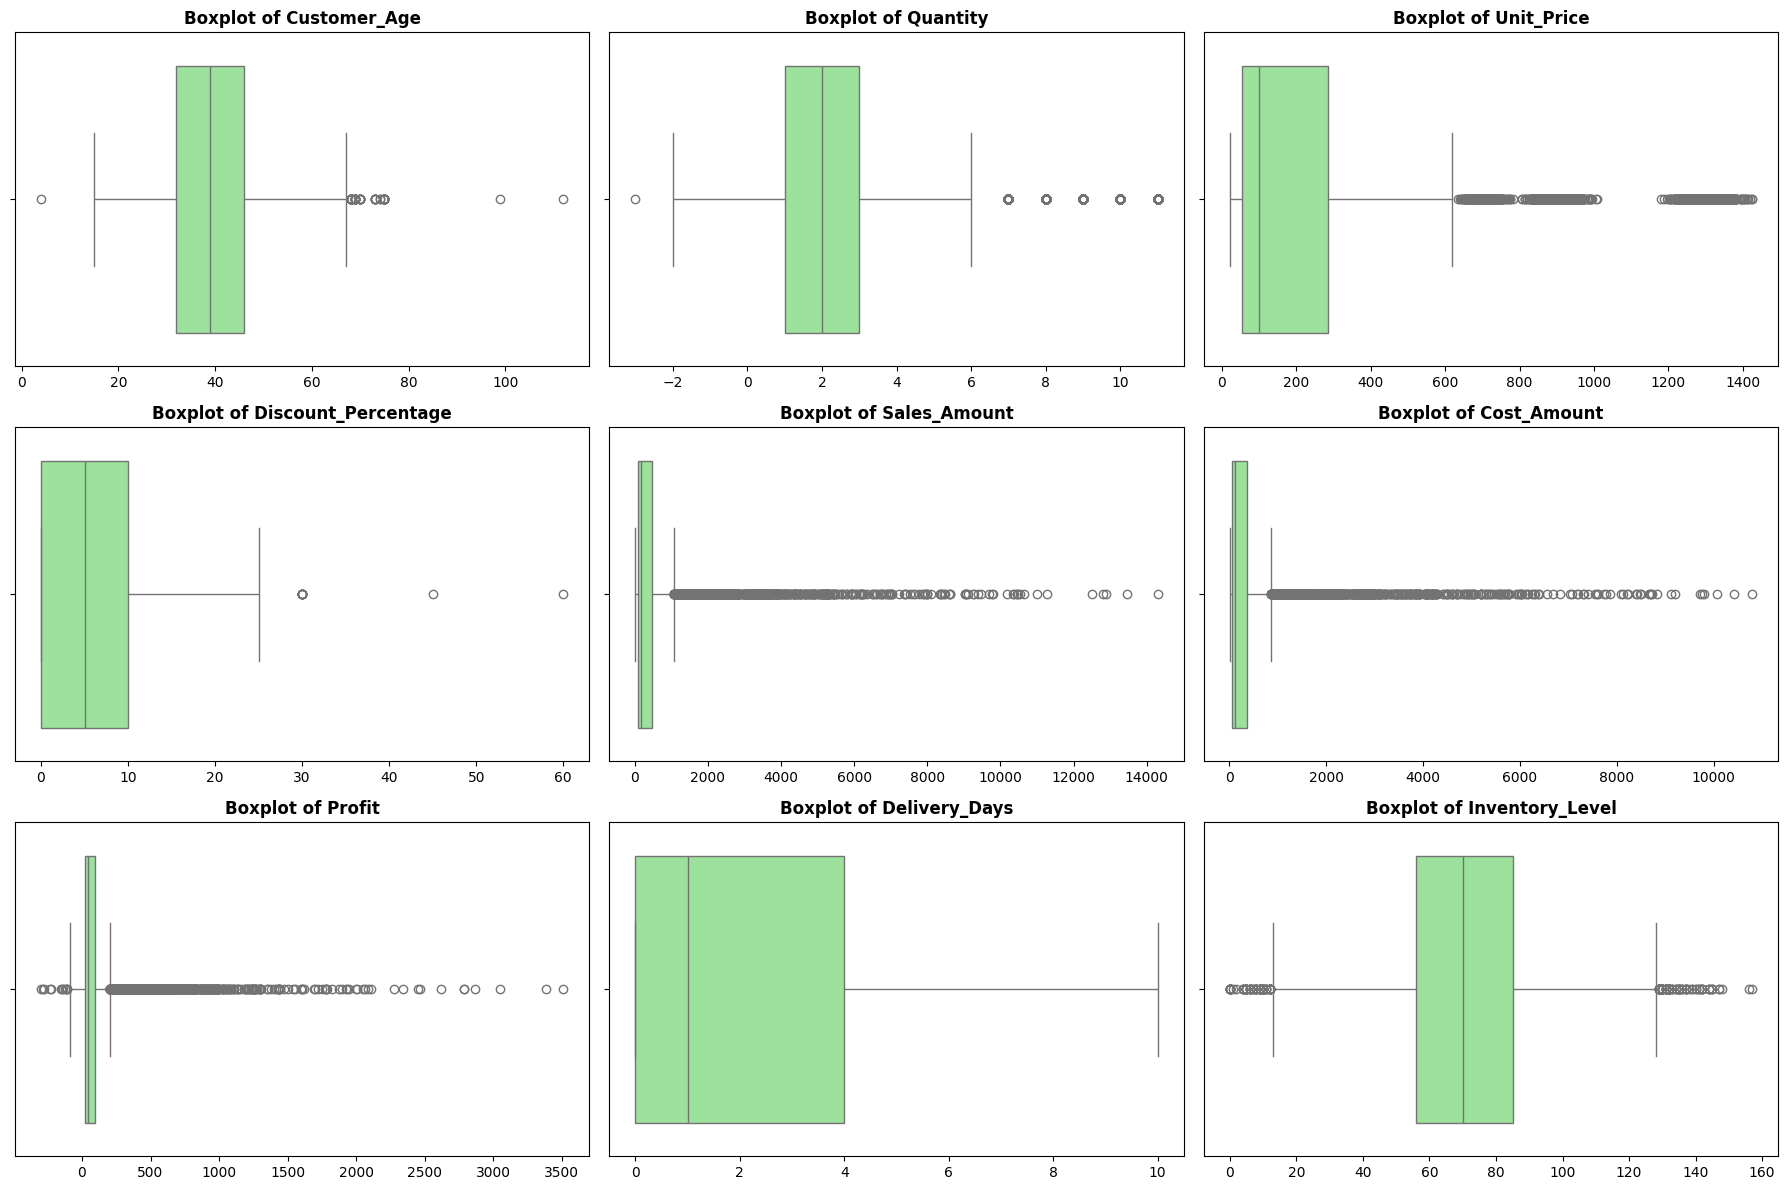

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# VISUALIZING OUTLIERS WITH BOXPLOTS
# ==========================================

# 1. Define the numerical columns in the exact order you specified
numerical_cols = [
    'Customer_Age', 'Quantity', 'Unit_Price', 'Discount_Percentage',
    'Sales_Amount', 'Cost_Amount', 'Profit', 'Delivery_Days', 'Inventory_Level'
]

# 2. Set up the figure size (3 rows, 3 columns = 9 slots)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

# 3. Loop through the columns and create a boxplot for each
for i, col in enumerate(numerical_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='lightgreen')
    axes[i].set_title(f'Boxplot of {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

plt.tight_layout()
plt.show()

In [27]:
# ==========================================
# SHOW ROWS WITH NEGATIVE QUANTITY
# ==========================================

# 1. Filter rows where Quantity is less than 0
negative_qty_rows = df[df['Quantity'] < 0]

# 2. Print the total count
print(f"Total rows with negative Quantity: {len(negative_qty_rows)}")
print("-" * 50)

# 3. Display relevant columns to investigate
# (Using to_string() to ensure all columns are visible without truncation)
print(negative_qty_rows[['Transaction_ID', 'Order_ID', 'Product_Name', 'Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Profit', 'Order_Status', 'Return_Flag']].to_string())

Total rows with negative Quantity: 3
--------------------------------------------------
      Transaction_ID  Order_ID      Product_Name  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  Profit Order_Status Return_Flag
3986       T02006553  O0103276      Air Purifier        -2      341.36                   20        273.09   17.16      Shipped          No
7487       T02011209  O0111209  Backup Drive 2TB        -1      127.86                   10        460.31   89.12   Processing          No
12156      T02004207  O0104207     Meeting Table        -3      913.91                    5        868.21  140.35    Completed          No


In [28]:
# ==========================================
# FINDING THE TRUE QUANTITY (BACK-CALCULATION)
# ==========================================

# 1. Filter negative quantities
neg_qty = df[df['Quantity'] < 0].copy()

# 2. Back-calculate the True Quantity using the formula
# Formula: Sales_Amount / (Unit_Price * (1 - Discount_Percentage/100))
neg_qty['Calculated_Quantity'] = neg_qty['Sales_Amount'] / (neg_qty['Unit_Price'] * (1 - (neg_qty['Discount_Percentage'] / 100)))

# 3. Display the comparison
print("=== TRUE QUANTITY ANALYSIS ===")
print(neg_qty[['Transaction_ID', 'Order_ID', 'Product_Name', 'Quantity', 'Calculated_Quantity', 'Unit_Price', 'Discount_Percentage', 'Sales_Amount', 'Profit', 'Order_Status', 'Return_Flag']].to_string())

=== TRUE QUANTITY ANALYSIS ===
      Transaction_ID  Order_ID      Product_Name  Quantity  Calculated_Quantity  Unit_Price  Discount_Percentage  Sales_Amount  Profit Order_Status Return_Flag
3986       T02006553  O0103276      Air Purifier        -2             1.000007      341.36                   20        273.09   17.16      Shipped          No
7487       T02011209  O0111209  Backup Drive 2TB        -1             4.000122      127.86                   10        460.31   89.12   Processing          No
12156      T02004207  O0104207     Meeting Table        -3             0.999995      913.91                    5        868.21  140.35    Completed          No


In [29]:
# ==========================================
# REPLACING NEGATIVE QUANTITY WITH TRUE VALUES
# ==========================================

# 1. Define the exact true quantities based on the back-calculation
# T02006553 -> 1
# T02011209 -> 4
# T02004207 -> 1

replacements = {
    'T02006553': 1,
    'T02011209': 4,
    'T02004207': 1
}

# 2. Apply the replacement using Transaction_ID as the reference
for trx_id, true_qty in replacements.items():
    df.loc[df['Transaction_ID'] == trx_id, 'Quantity'] = true_qty

In [30]:
# ==========================================
# REMOVE UNWANTED COLUMN
# ==========================================

# Drop the 'True_Quantity' column if it exists
if 'True_Quantity' in df.columns:
    df = df.drop(columns=['True_Quantity'])
    print("Column 'True_Quantity' has been successfully removed.")
else:
    print("Column 'True_Quantity' does not exist.")

# Verify the total number of columns
print(f"Total columns now: {len(df.columns)}")

Column 'True_Quantity' does not exist.
Total columns now: 36


In [31]:
# ==========================================
# VIEW ALL COLUMNS FOR SPECIFIC TRANSACTIONS
# ==========================================

# 1. List of the specific Transaction_IDs
target_ids = ['T02006553', 'T02011209', 'T02004207']

# 2. Filter the dataframe for these IDs
specific_rows = df[df['Transaction_ID'].isin(target_ids)]

# 3. Print the entire row (all columns) using to_string()
print("=== FULL DATA FOR SPECIFIC TRANSACTIONS ===")
print(specific_rows.to_string(index=False))

=== FULL DATA FOR SPECIFIC TRANSACTIONS ===
Transaction_ID Order_ID Customer_ID   Customer_Name  Customer_Age Customer_Gender Customer_Segment Order_Date Order_Time Sales_Channel Store_ID       Store_Name        Country                 Region       City Product_ID     Product_Name Product_Category Product_Subcategory  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  Cost_Amount  Profit Payment_Method Order_Status Shipping_Method  Delivery_Days Return_Flag Return_Reason Sales_Representative Promotion_Code  Customer_Rating  Inventory_Level  Order_Year
     T02006553 O0103276      C04087      Theo Green          31.0          Female         Consumer 2025-11-29   09:25:49        Online   VAN-01   Vancouver West         Canada       British Columbia  Vancouver       P022     Air Purifier       Appliances         Home Office         1      341.36                   20        273.09       255.93   17.16    Credit Card      Shipped        Standard            6.0          No           Na

In [32]:
# ==========================================
# FILTER ROWS WITH AGE BELOW 10 OR ABOVE 90
# ==========================================

# Filter the dataframe based on the conditions
age_filter = df[(df['Customer_Age'] < 10) | (df['Customer_Age'] > 90)]

# Display the rows
print(f"Total rows: {len(age_filter)}")
print(age_filter.to_string(index=False))

Total rows: 3
Transaction_ID Order_ID Customer_ID      Customer_Name  Customer_Age Customer_Gender Customer_Segment Order_Date Order_Time Sales_Channel Store_ID           Store_Name       Country           Region        City Product_ID      Product_Name Product_Category Product_Subcategory  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  Cost_Amount  Profit Payment_Method Order_Status Shipping_Method  Delivery_Days Return_Flag Return_Reason Sales_Representative Promotion_Code  Customer_Rating  Inventory_Level  Order_Year
     T02003795 O0101897      C02947 Alexander Williams         112.0          Female         Consumer 2025-06-30   12:39:52  Retail Store   TOR-01      Toronto Central        Canada          Ontario     Toronto       P002 ProBook 16 Laptop      Electronics             Laptops         2     1365.30                    0       2730.60      2066.23  664.37    Credit Card    Cancelled        Standard            2.0          No           NaN       Amelia Jackson  BL

In [33]:
# ==========================================
# CHECK THE CORRECT REPLACEMENT VALUES
# ==========================================

# 1. Get all unique ages and sort them
sorted_ages = sorted(df['Customer_Age'].unique())

# 2. Find the values based on your rule (excluding 4, 99, 112)
# We just look at the sorted list to see what the next numbers are
print("Smallest ages in dataset:", sorted_ages[:5])
print("Largest ages in dataset:", sorted_ages[-5:])

Smallest ages in dataset: [np.float64(4.0), np.float64(15.0), np.float64(18.0), np.float64(19.0), np.float64(20.0)]
Largest ages in dataset: [np.float64(73.0), np.float64(74.0), np.float64(75.0), np.float64(99.0), np.float64(112.0)]


In [34]:
# ==========================================
# FIX IMPOSSIBLE AGES
# ==========================================

# Replace age 4 with the second smallest age (15)
df.loc[df['Customer_Age'] == 4.0, 'Customer_Age'] = 15.0

# Replace age 99 and 112 with the third largest age (75)
df.loc[df['Customer_Age'] == 99.0, 'Customer_Age'] = 75.0
df.loc[df['Customer_Age'] == 112.0, 'Customer_Age'] = 75.0

In [35]:
# ==========================================
# VIEW ALL COLUMNS FOR SPECIFIC TRANSACTIONS
# ==========================================

# 1. List of the specific Transaction_IDs
target_ids = ['T02003795', 'T02010919', 'T02002935']

# 2. Filter the dataframe for these IDs
specific_rows = df[df['Transaction_ID'].isin(target_ids)]

# 3. Print the entire row (all columns) using to_string()
print("=== FULL DATA FOR SPECIFIC TRANSACTIONS ===")
print(specific_rows.to_string(index=False))

=== FULL DATA FOR SPECIFIC TRANSACTIONS ===
Transaction_ID Order_ID Customer_ID      Customer_Name  Customer_Age Customer_Gender Customer_Segment Order_Date Order_Time Sales_Channel Store_ID           Store_Name       Country           Region        City Product_ID      Product_Name Product_Category Product_Subcategory  Quantity  Unit_Price  Discount_Percentage  Sales_Amount  Cost_Amount  Profit Payment_Method Order_Status Shipping_Method  Delivery_Days Return_Flag Return_Reason Sales_Representative Promotion_Code  Customer_Rating  Inventory_Level  Order_Year
     T02003795 O0101897      C02947 Alexander Williams          75.0          Female         Consumer 2025-06-30   12:39:52  Retail Store   TOR-01      Toronto Central        Canada          Ontario     Toronto       P002 ProBook 16 Laptop      Electronics             Laptops         2     1365.30                    0       2730.60      2066.23  664.37    Credit Card    Cancelled        Standard            2.0          No         

## **C. Feature Engineering**

In [36]:
import numpy as np

# ==========================================
# FEATURE ENGINEERING (CREATING NEW COLUMNS)
# ==========================================

# 1. Customer_Age_Group
# Define the bins and labels
bins = [0, 19, 39, 59, 100]
labels = ['< 20', '20 - 39', '40 - 59', '>= 60']
df['Customer_Age_Group'] = pd.cut(df['Customer_Age'], bins=bins, labels=labels)

# 2. Order_Month
# Extracts the month name (e.g., 'January', 'May')
df['Order_Month'] = df['Order_Date'].dt.month_name()

# 3. Order_Day
# Extracts the day name (e.g., 'Monday', 'Friday')
df['Order_Day'] = df['Order_Date'].dt.day_name()

# 4. Discount_Amount
# Formula: (Quantity * Unit_Price) - Sales_Amount
df['Discount_Amount'] = (df['Quantity'] * df['Unit_Price']) - df['Sales_Amount']

# 5. Profit_Margin_Percentage (%)
# Formula: (Profit / Sales_Amount) * 100
# We use np.where to avoid division by zero if Sales_Amount is 0
df['Profit_Margin_Percentage'] = np.where(df['Sales_Amount'] > 0, ((df['Profit'] / df['Sales_Amount']) * 100).round(2), 0)

# ==========================================
# VERIFICATION: SHOW SAMPLE DATA
# ==========================================
print("=== SAMPLE DATA WITH NEW FEATURES ===")
new_cols = ['Customer_Age', 'Customer_Age_Group', 'Order_Date', 'Order_Month', 'Order_Day', 'Sales_Amount', 'Discount_Amount', 'Profit_Margin_Percentage']
print(df[new_cols].head(10).to_string(index=False))

=== SAMPLE DATA WITH NEW FEATURES ===
 Customer_Age Customer_Age_Group Order_Date Order_Month Order_Day  Sales_Amount  Discount_Amount  Profit_Margin_Percentage
         28.0            20 - 39 2022-10-06     October  Thursday        162.05             8.53                     28.66
         46.0            40 - 59 2024-06-03        June    Monday        300.13            52.97                     21.03
         42.0            40 - 59 2024-12-19    December  Thursday         74.66            13.18                      2.00
         18.0               < 20 2025-10-05     October    Sunday       1078.46           190.28                     16.74
         37.0            20 - 39 2022-09-13   September   Tuesday        237.03            41.81                     30.41
         42.0            40 - 59 2023-03-27       March    Monday         75.96             4.00                     34.06
         46.0            40 - 59 2022-07-25        July    Monday        118.64             6.25     

In [37]:
# ==========================================
# REORDERING COLUMNS BASED ON POSITIONS
# ==========================================

# --- STEP 1: Reorder the newly created columns ---
# 1. Customer_Age_Group (Between Customer_Age and Customer_Gender)
age_group_data = df.pop('Customer_Age_Group')
idx_age = df.columns.get_loc('Customer_Age')
df.insert(idx_age + 1, 'Customer_Age_Group', age_group_data)

# 2. Order_Day (Right of Order_Date)
order_day_data = df.pop('Order_Day')
idx_date = df.columns.get_loc('Order_Date')
df.insert(idx_date + 1, 'Order_Day', order_day_data)

# 3. Order_Month (Right of Order_Day)
order_month_data = df.pop('Order_Month')
# Notice that Order_Day is now at idx_date + 1, so Order_Month goes at idx_date + 2
df.insert(idx_date + 2, 'Order_Month', order_month_data)

# 4. Discount_Amount (Between Discount_Percentage and Sales_Amount)
discount_amount_data = df.pop('Discount_Amount')
idx_discount_pct = df.columns.get_loc('Discount_Percentage')
df.insert(idx_discount_pct + 1, 'Discount_Amount', discount_amount_data)

# 5. Profit_Margin_Percentage (Between Profit and Payment_Method)
profit_margin_data = df.pop('Profit_Margin_Percentage')
idx_profit = df.columns.get_loc('Profit')
df.insert(idx_profit + 1, 'Profit_Margin_Percentage', profit_margin_data)

# --- STEP 2: Move existing columns ---
# Move 'Order_Year' to the right of 'Order_Month'
# First, pop the column and then insert it at the specific index
order_year_data = df.pop('Order_Year')
# We insert it at the position right after Order_Month
# (We'll find the exact index of Order_Month dynamically)
idx_order_month = df.columns.get_loc('Order_Month')
df.insert(idx_order_month + 1, 'Order_Year', order_year_data)

# ==========================================
# VERIFICATION
# ==========================================
print("=== UPDATED COLUMN ORDER ===")
print("Total columns:", len(df.columns))
print("\nHere are the relevant columns in their new order:")
# Print a few specific columns to verify
verify_cols = ['Customer_Age', 'Customer_Age_Group', 'Customer_Gender',
               'Order_Date', 'Order_Day', 'Order_Month', 'Order_Year',
               'Discount_Percentage', 'Discount_Amount', 'Sales_Amount',
               'Profit', 'Profit_Margin_Percentage', 'Payment_Method']
print(df[verify_cols].head(3).to_string())

=== UPDATED COLUMN ORDER ===
Total columns: 41

Here are the relevant columns in their new order:
   Customer_Age Customer_Age_Group Customer_Gender Order_Date Order_Day Order_Month  Order_Year  Discount_Percentage  Discount_Amount  Sales_Amount  Profit  Profit_Margin_Percentage Payment_Method
0          28.0            20 - 39            Male 2022-10-06  Thursday     October        2022                    5             8.53        162.05   46.44                     28.66    Credit Card
1          46.0            40 - 59          Female 2024-06-03    Monday        June        2024                   15            52.97        300.13   63.13                     21.03     Debit Card
2          42.0            40 - 59            Male 2024-12-19  Thursday    December        2024                   15            13.18         74.66    1.49                      2.00    Credit Card


In [38]:
df.head()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Age_Group,Customer_Gender,Customer_Segment,Order_Date,Order_Day,...,Payment_Method,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level
0,T02016694,O0116694,C01482,Sophia Smith,28.0,20 - 39,Male,Consumer,2022-10-06,Thursday,...,Credit Card,Completed,Standard,4.0,No,NaN,James Anderson,SAVE10,4.0,81.0
1,T02016374,O0108187,C01591,Hannah King,46.0,40 - 59,Female,Consumer,2024-06-03,Monday,...,Debit Card,Completed,Standard,6.0,No,NaN,Ella Lewis,NaN,5.0,123.0
2,T02004099,O0104099,C04140,Emma Wilson,42.0,40 - 59,Male,Consumer,2024-12-19,Thursday,...,Credit Card,Shipped,Standard,4.0,No,NaN,Liam Davis,NaN,4.0,93.0
3,T02010280,O0110280,C03663,Daniel Clark,18.0,< 20,Male,Corporate,2025-10-05,Sunday,...,PayPal,Completed,Next Day,2.0,No,NaN,Grace Harris,HOLIDAY20,NaN,59.0
4,T02012685,O0112685,C02749,Sophia Smith,37.0,20 - 39,Male,Returning Customer,2022-09-13,Tuesday,...,Apple Pay,Completed,Express,2.0,No,NaN,Sophia Brown,NaN,2.0,56.0


In [39]:
df.tail()

,Transaction_ID,Order_ID,Customer_ID,Customer_Name,Customer_Age,Customer_Age_Group,Customer_Gender,Customer_Segment,Order_Date,Order_Day,...,Payment_Method,Order_Status,Shipping_Method,Delivery_Days,Return_Flag,Return_Reason,Sales_Representative,Promotion_Code,Customer_Rating,Inventory_Level
18040,T02006253,O0106253,C03487,Ella Adams,32.0,20 - 39,Male,New Customer,2022-01-11,Tuesday,...,Credit Card,Completed,Express,2.0,No,NaN,Emma Carter,MOM15,5.0,52.0
18041,T02005688,O0102844,C00418,Jack Jones,32.0,20 - 39,Male,Returning Customer,2023-10-09,Monday,...,Credit Card,Processing,Standard,3.0,No,NaN,Emma Carter,SAVE10,4.0,107.0
18042,T02011672,O0111672,C03311,Oscar Williams,37.0,20 - 39,Male,Corporate,2025-04-02,Wednesday,...,Apple Pay,Completed,Standard,6.0,No,NaN,Sophia Brown,SAVE10,2.0,58.0
18043,T02013094,O0113094,C01590,Benjamin Moore,21.0,20 - 39,Female,New Customer,2022-06-08,Wednesday,...,Debit Card,Completed,Standard,7.0,No,NaN,Noah Wilson,BLACKFRIDAY25,3.0,32.0
18044,T02011617,O0111617,C01479,Lucas Allen,55.0,40 - 59,Male,Consumer,2025-06-30,Monday,...,PayPal,Completed,Pickup,0.0,No,NaN,Grace Harris,NaN,5.0,73.0


In [40]:
# ==========================================
# SAVE AND DOWNLOAD AS EXCEL (.xlsx)
# ==========================================
from google.colab import files

# 1. Define the file name
file_name = "Cleaned Sales Transaction History 2022–2025.xlsx"

# 2. Save the dataframe to Excel format
# (index=False agar nomor urut tidak ikut tersimpan)
df.to_excel(file_name, index=False)

# 3. Download the file
files.download(file_name)

print(f"File '{file_name}' has been downloaded successfully as an Excel file!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

File 'Cleaned Sales Transaction History 2022–2025.xlsx' has been downloaded successfully as an Excel file!


## **D. Exploratory Data Analysis**

### **1. Geographic Performance**

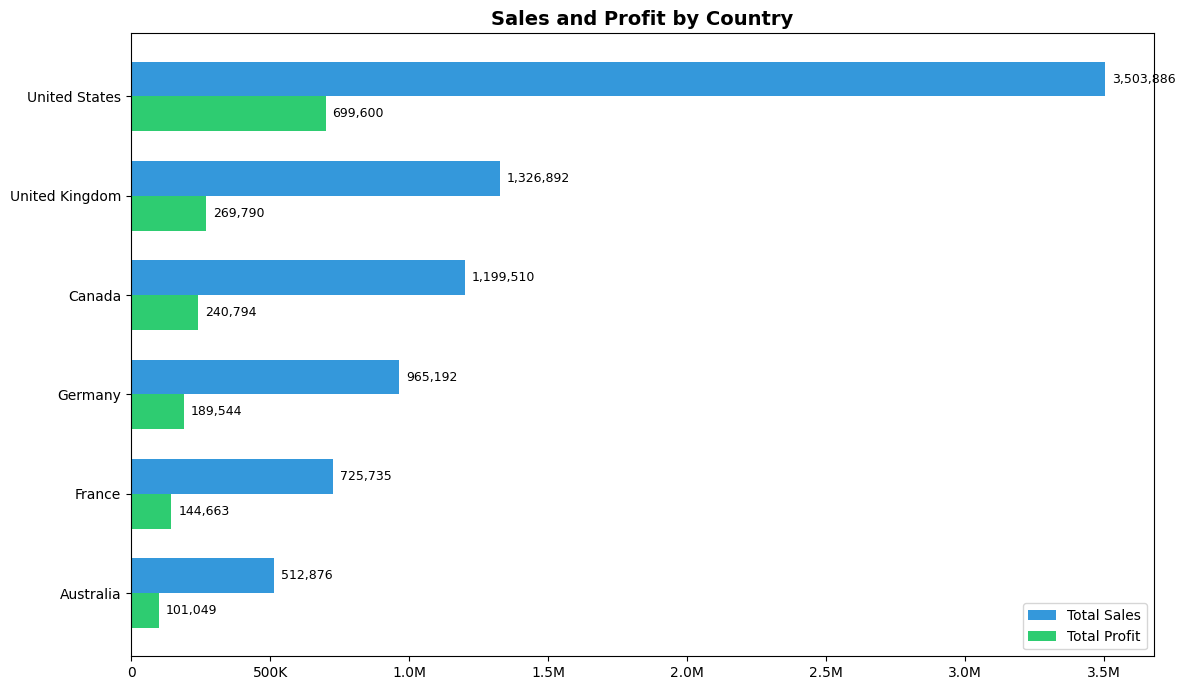

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

# ===============================
# SALES AND PROFIT BY COUNTRY
# ===============================

# 1. Group data by Country and sum Sales & Profit
country_perf = df.groupby('Country')[['Sales_Amount', 'Profit']].sum().sort_values(by='Sales_Amount', ascending=True)

# 2. Set up the bar chart
y = np.arange(len(country_perf.index))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# 3. Create the horizontal bars
bars1 = ax.barh(y + height/2, country_perf['Sales_Amount'], height, label='Total Sales', color='#3498db')
bars2 = ax.barh(y - height/2, country_perf['Profit'], height, label='Total Profit', color='#2ecc71')

# 4. Format X-axis
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# 5. Add labels
ax.set_title('Sales and Profit by Country', fontweight='bold', fontsize=14)
ax.set_yticks(y)
ax.set_yticklabels(country_perf.index)
ax.legend()

# 6. Add value labels at the end of bars
for bars in [bars1, bars2]:
    for bar in bars:
        width_val = bar.get_width()
        ax.annotate(f'{width_val:,.0f}',
                    xy=(width_val, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

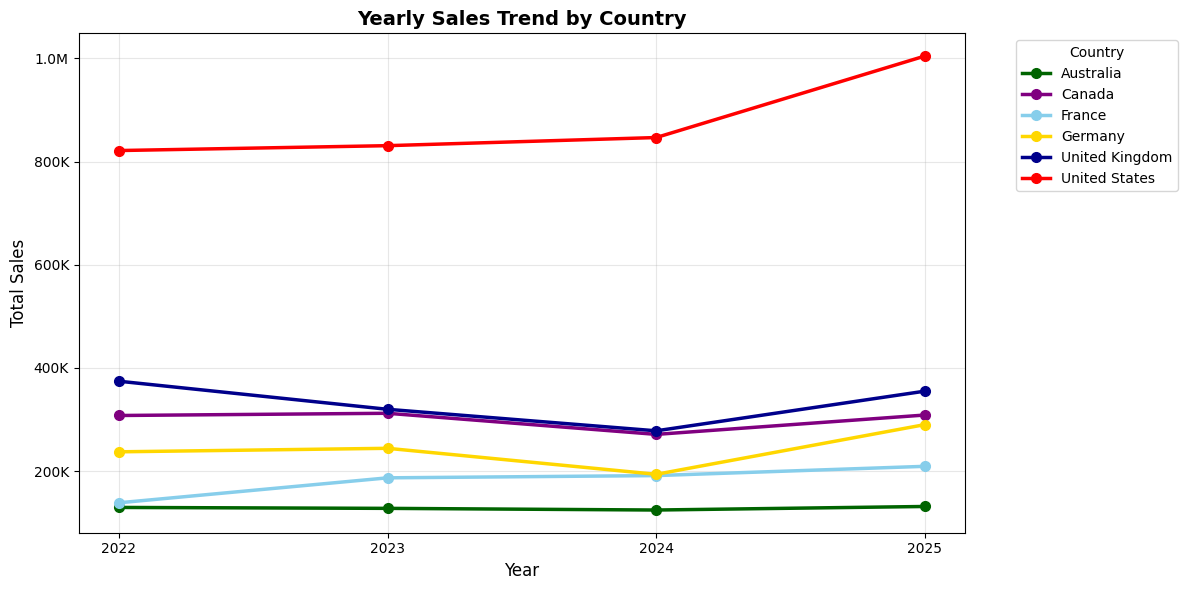

In [42]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ==============================
# YEARLY SALES TREND BY COUNTRY
# ==============================

# 1. Group data by Year and Country, then sum Sales_Amount
trend_data = df.groupby(['Order_Year', 'Country'])['Sales_Amount'].sum().unstack()

# 2. Set up the specific colors requested
color_map = {
    'United States': 'red',
    'United Kingdom': 'darkblue',
    'Canada': 'purple',
    'Germany': 'gold',
    'France': 'skyblue',
    'Australia': 'darkgreen'
}

# 3. Set up the plot
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Plot each line with specific colors and markers
for country in trend_data.columns:
    if country in color_map:
        ax.plot(trend_data.index, trend_data[country],
                marker='o',          # Add dots at each data point
                linewidth=2.5,       # Thickness of the line
                markersize=7,        # Size of the dots
                label=country,
                color=color_map[country])

# 5. Format Y-Axis
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# 6. Add labels and title
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)
ax.set_title('Yearly Sales Trend by Country', fontweight='bold', fontsize=14)
ax.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend placed outside to avoid covering lines
ax.grid(True, alpha=0.3)

# 7. Ensure X-axis only shows the years present in data
ax.set_xticks(trend_data.index)

plt.tight_layout()
plt.show()

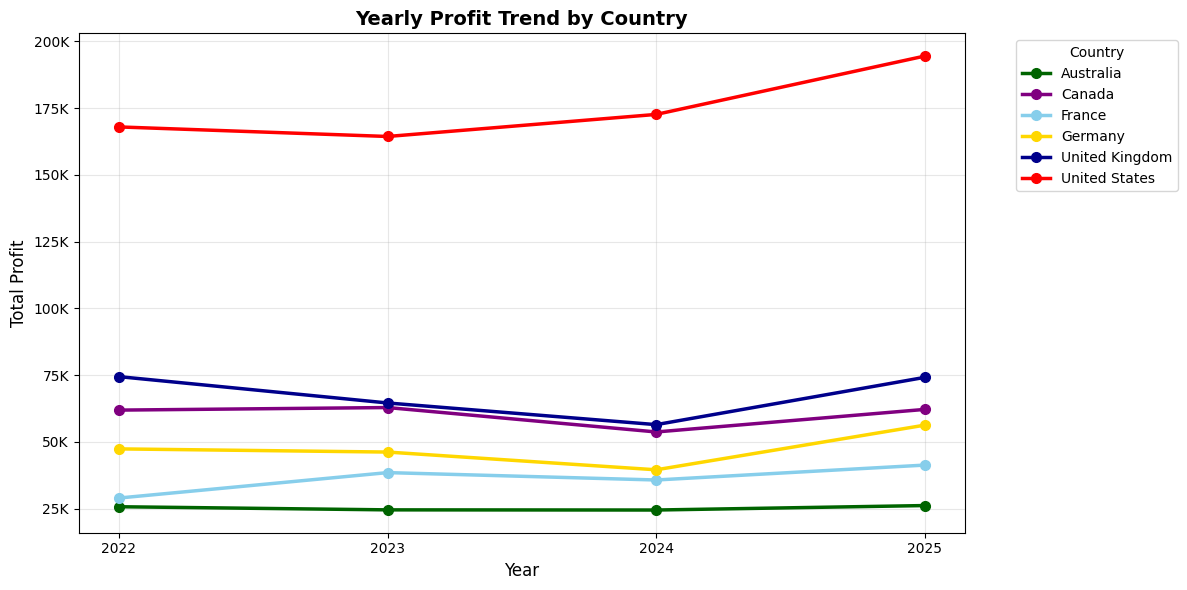

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ===============================
# YEARLY PROFIT TREND BY COUNTRY
# ===============================

# 1. Group data by Year and Country, then sum Profit
trend_data = df.groupby(['Order_Year', 'Country'])['Profit'].sum().unstack()

# 2. Set up the specific colors requested
color_map = {
    'United States': 'red',
    'United Kingdom': 'darkblue',
    'Canada': 'purple',
    'Germany': 'gold',
    'France': 'skyblue',
    'Australia': 'darkgreen'
}

# 3. Set up the plot
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Plot each line with specific colors and markers
for country in trend_data.columns:
    if country in color_map:
        ax.plot(trend_data.index, trend_data[country],
                marker='o',          # Add dots at each data point
                linewidth=2.5,       # Thickness of the line
                markersize=7,        # Size of the dots
                label=country,
                color=color_map[country])

# 5. Format Y-Axis
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# 6. Add labels and title
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Total Profit', fontsize=12)
ax.set_title('Yearly Profit Trend by Country', fontweight='bold', fontsize=14)
ax.legend(title='Country', bbox_to_anchor=(1.05, 1), loc='upper left') # Legend placed outside to avoid covering lines
ax.grid(True, alpha=0.3)

# 7. Ensure X-axis only shows the years present in data
ax.set_xticks(trend_data.index)

plt.tight_layout()
plt.show()

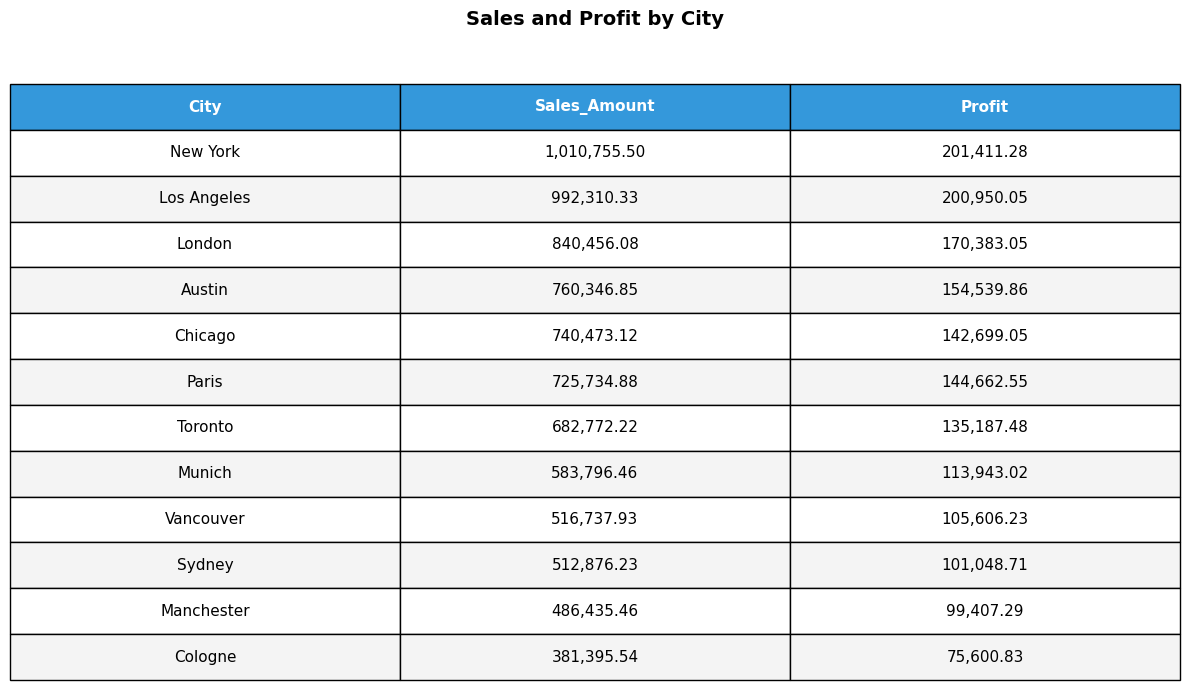

In [44]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# SALES AND PROFIT BY CITY
# =========================

# 1. Group data by City and sum Sales & Profit
city_perf = df.groupby('City')[['Sales_Amount', 'Profit']].sum()

# 2. Sort by Sales_Amount descending
city_perf = city_perf.sort_values(by='Sales_Amount', ascending=False)

# 3. Format numbers to 2 decimal places with commas
city_perf['Sales_Amount'] = city_perf['Sales_Amount'].apply(lambda x: f"{x:,.2f}")
city_perf['Profit'] = city_perf['Profit'].apply(lambda x: f"{x:,.2f}")

# 4. Reset index so 'City' becomes a regular column
city_perf = city_perf.reset_index()

# 5. Set up the figure
fig, ax = plt.subplots(figsize=(12, 7))
ax.axis('off') # Hide the axes

# 6. Create the table
table = ax.table(cellText=city_perf.values,
                 colLabels=city_perf.columns,
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 0.95]) # Bounding box to make it wide

# 7. Style the table
table.auto_set_font_size(False)
table.set_fontsize(11)

# Style header row
for (i, j), cell in table.get_celld().items():
    if i == 0: # Header row
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#3498db') # Blue header
    else:
        cell.set_facecolor('#f4f4f4' if i % 2 == 0 else 'white') # Zebra stripes
    cell.set_edgecolor('black')

# 8. Add a bold title
plt.title('Sales and Profit by City', fontweight='bold', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

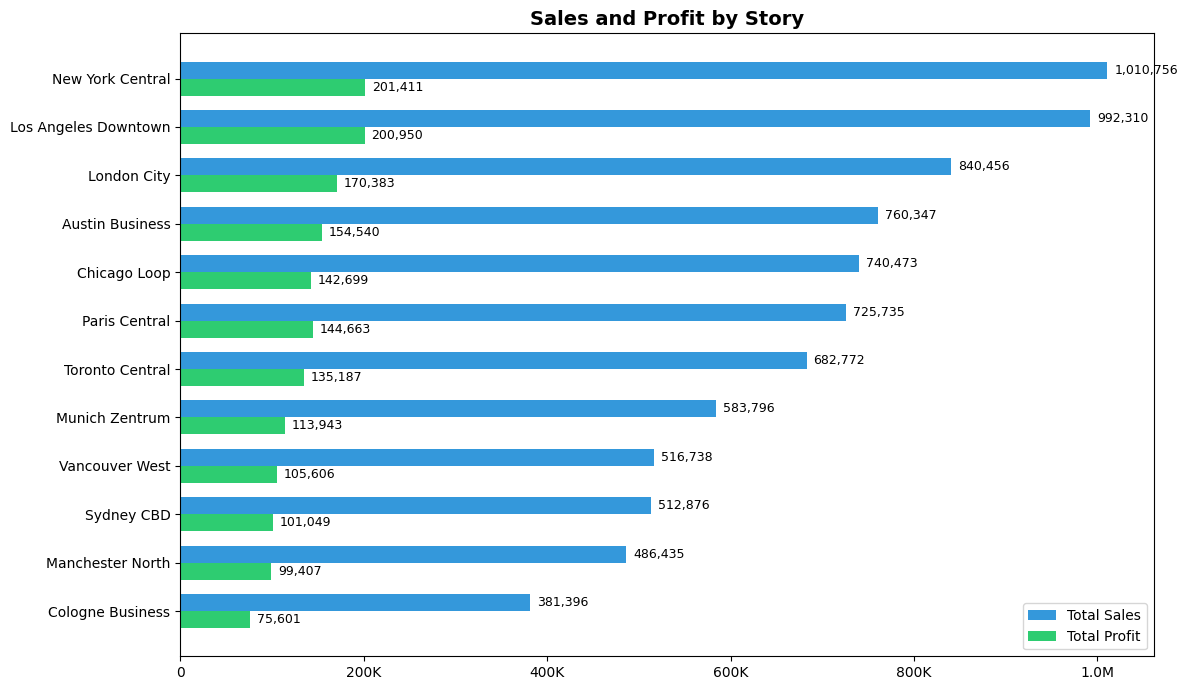

In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker

# ==========================
# SALES AND PROFIT BY STORE
# ==========================

# 1. Group data by Store and sum Sales & Profit
country_perf = df.groupby('Store_Name')[['Sales_Amount', 'Profit']].sum().sort_values(by='Sales_Amount', ascending=True)

# 2. Set up the bar chart
y = np.arange(len(country_perf.index))
height = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# 3. Create the horizontal bars
bars1 = ax.barh(y + height/2, country_perf['Sales_Amount'], height, label='Total Sales', color='#3498db')
bars2 = ax.barh(y - height/2, country_perf['Profit'], height, label='Total Profit', color='#2ecc71')

# 4. Format X-axis
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# 5. Add labels
ax.set_title('Sales and Profit by Story', fontweight='bold', fontsize=14)
ax.set_yticks(y)
ax.set_yticklabels(country_perf.index)
ax.legend()

# 6. Add value labels at the end of bars
for bars in [bars1, bars2]:
    for bar in bars:
        width_val = bar.get_width()
        ax.annotate(f'{width_val:,.0f}',
                    xy=(width_val, bar.get_y() + bar.get_height() / 2),
                    xytext=(5, 0),
                    textcoords="offset points",
                    ha='left', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### **2. Customer Performance**

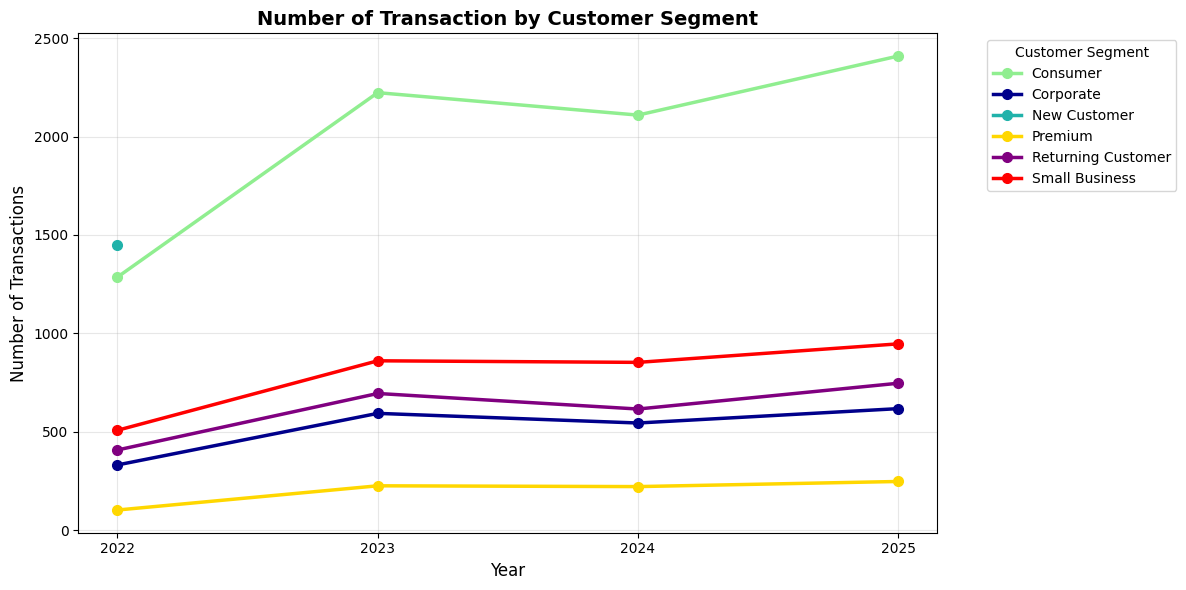

In [46]:
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# NUMBER OF TRANSACTION BY CUSTOMER SEGMENT
# ==========================================

# 1. Group data and count transactions
trend_tx = df.groupby(['Order_Year', 'Customer_Segment'])['Transaction_ID'].count().unstack()

# 2. Define colors
color_map = {
    'Consumer': 'lightgreen',
    'Small Business': 'red',
    'Returning Customer': 'purple',
    'Corporate': 'darkblue',
    'New Customer': 'lightseagreen',
    'Premium': 'gold'
}

# 3. Create plot
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Plot each line
for segment in trend_tx.columns:
    if segment in color_map:
        ax.plot(trend_tx.index, trend_tx[segment],
                marker='o',
                linewidth=2.5,
                markersize=7,
                label=segment,
                color=color_map[segment])

# 5. Formatting
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of Transactions', fontsize=12)
ax.set_title('Number of Transaction by Customer Segment', fontweight='bold', fontsize=14)
ax.legend(title='Customer Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)

# Ensure X-axis shows only years
ax.set_xticks(trend_tx.index)

plt.tight_layout()
plt.show()

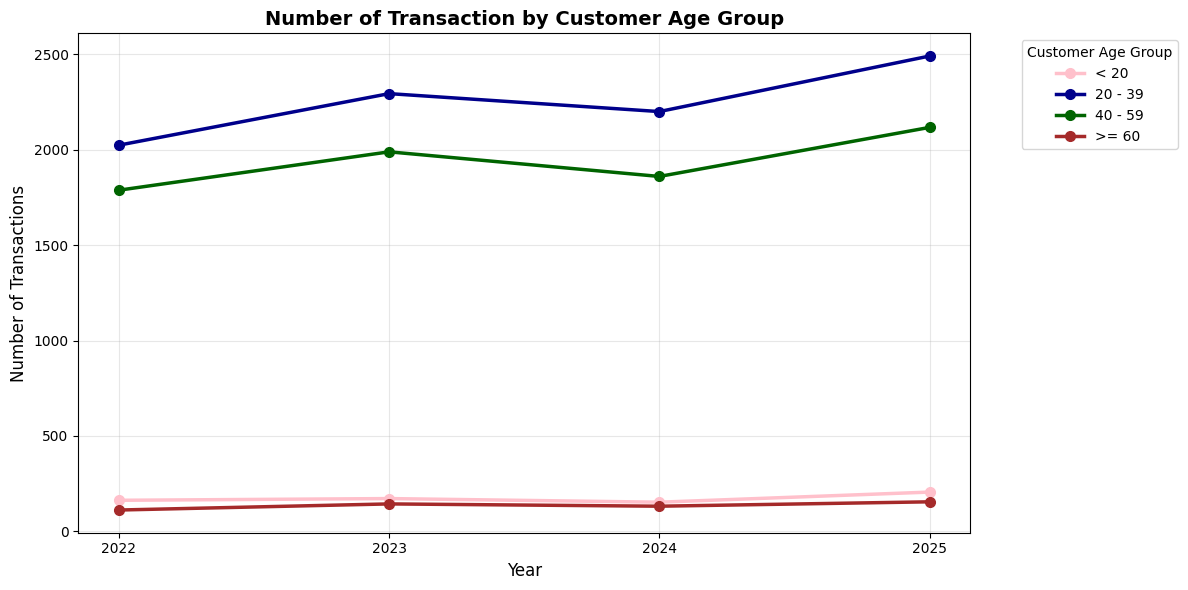

In [47]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================
# NUMBER OF TRANSACTION BY CUSTOMER AGE GROUP
# ============================================

# 1. Group data and count transactions
trend_tx = df.groupby(['Order_Year', 'Customer_Age_Group'], observed=True)['Transaction_ID'].count().unstack()

# 2. Define colors
color_map = {
    '< 20': 'pink',
    '20 - 39': 'darkblue',
    '40 - 59': 'darkgreen',
    '>= 60': 'brown'
}

# 3. Create plot
fig, ax = plt.subplots(figsize=(12, 6))

# 4. Plot each line
for segment in trend_tx.columns:
    if segment in color_map:
        ax.plot(trend_tx.index, trend_tx[segment],
                marker='o',
                linewidth=2.5,
                markersize=7,
                label=segment,
                color=color_map[segment])

# 5. Formatting
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of Transactions', fontsize=12)
ax.set_title('Number of Transaction by Customer Age Group', fontweight='bold', fontsize=14)
ax.legend(title='Customer Age Group', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)

# Ensure X-axis shows only years
ax.set_xticks(trend_tx.index)

plt.tight_layout()
plt.show()

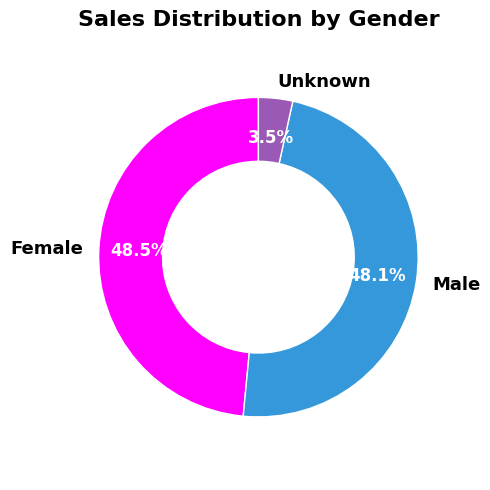

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# =============================
# SALES DISTRIBUTION BY GENDER
# =============================

# 1. Group data by Gender and sum Sales_Amount
gender_sales = df.groupby('Customer_Gender')['Sales_Amount'].sum()

# 2. Set up colors based on instructions
color_map = {
    'Female': '#ff00ff',     # Magenta
    'Male': '#3498db',       # Blue
    'Unknown': '#9b59b6'     # Purple
}
# Map colors to the data
colors = [color_map.get(gender, '#cccccc') for gender in gender_sales.index]

# 3. Create Donut Chart
fig, ax = plt.subplots(figsize=(5, 5))

# Pie chart (with 'wedgeprops' for donut hole)
wedges, texts, autotexts = ax.pie(
    gender_sales,
    labels=gender_sales.index,
    autopct='%1.1f%%',      # Format percentage with 1 decimal
    startangle=90,          # Start from top
    colors=colors,
    pctdistance=0.75,       # Distance of percentage text from center
    wedgeprops=dict(width=0.4, edgecolor='w') # width=0.4 creates the donut hole
)

# 4. Customize text (make it bold and clean)
for text in texts:
    text.set_fontsize(13)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    autotext.set_color('white') # White text inside the colored ring

# 5. Add title
ax.set_title('Sales Distribution by Gender', fontweight='bold', fontsize=16)

# 6. Draw a white circle in the middle for a cleaner donut look
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

# Ensure it's a perfect circle
ax.axis('equal')

plt.tight_layout()
plt.show()

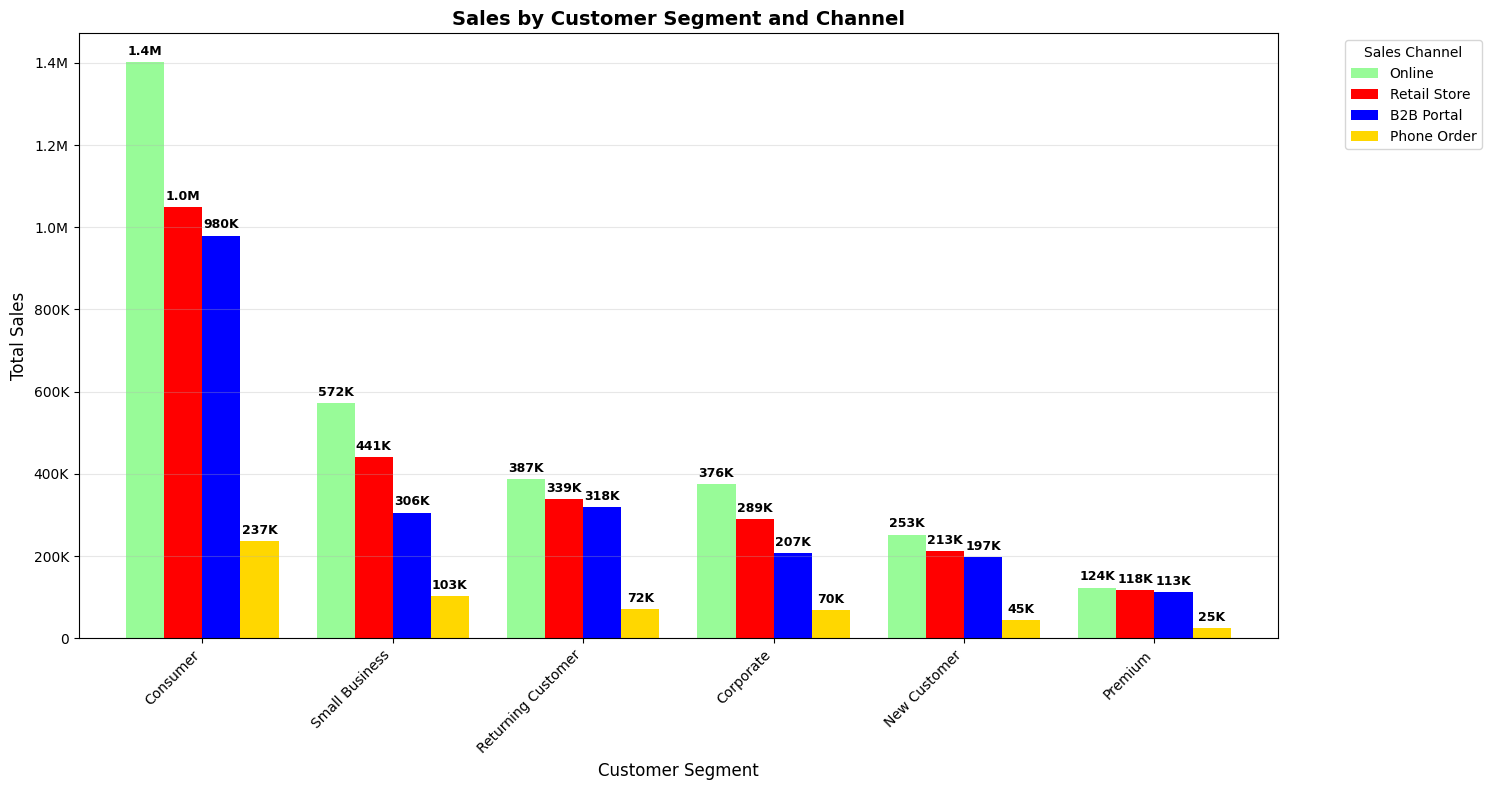

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# =============================
# SALES BY SEGMENT AND CHANNEL
# =============================

# 1. Group data
segment_channel = df.groupby(['Customer_Segment', 'Sales_Channel'])['Sales_Amount'].sum().unstack()

# 2. Reorder Customer Segments
segment_order = ['Consumer', 'Small Business', 'Returning Customer', 'Corporate', 'New Customer', 'Premium']
segment_channel = segment_channel.reindex([s for s in segment_order if s in segment_channel.index])

# 3. Reorder Channels and define Colors
channel_order = ['Online', 'Retail Store', 'B2B Portal', 'Phone Order']
channel_channel = [c for c in channel_order if c in segment_channel.columns]
segment_channel = segment_channel[channel_channel]

color_map = {
    'Online': '#98FB98',       # Light Green
    'Retail Store': '#FF0000', # Red
    'B2B Portal': '#0000FF',   # Blue
    'Phone Order': '#FFD700'   # Gold / Yellow
}
colors = [color_map[c] for c in channel_channel]

# 4. Create Grouped Bar Chart
fig, ax = plt.subplots(figsize=(15, 8))

# Plotting grouped bars (store the plot result to get axis containers)
plot = segment_channel.plot(kind='bar', color=colors, ax=ax, width=0.8)

# 5. Add Value Labels on top of bars
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# Loop through each container (each channel's bars)
for c in ax.containers:
    # Get labels for each bar and format them
    labels = [millions_formatter(v.get_height()) if v.get_height() > 0 else '' for v in c]

    # Annotate the bars
    ax.bar_label(c, labels=labels, label_type='edge', padding=3, fontsize=9, fontweight='bold')

# 6. Formatting
ax.set_xlabel('Customer Segment', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)
ax.set_title('Sales by Customer Segment and Channel', fontweight='bold', fontsize=14)

# Format Y-Axis to M / K
ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# Customizing Legend and Grid
ax.legend(title='Sales Channel', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Rotate X-axis labels
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

/tmp/ipykernel_831/4025543464.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_channel = df.groupby(['Customer_Age_Group', 'Sales_Channel'])['Sales_Amount'].sum().unstack()


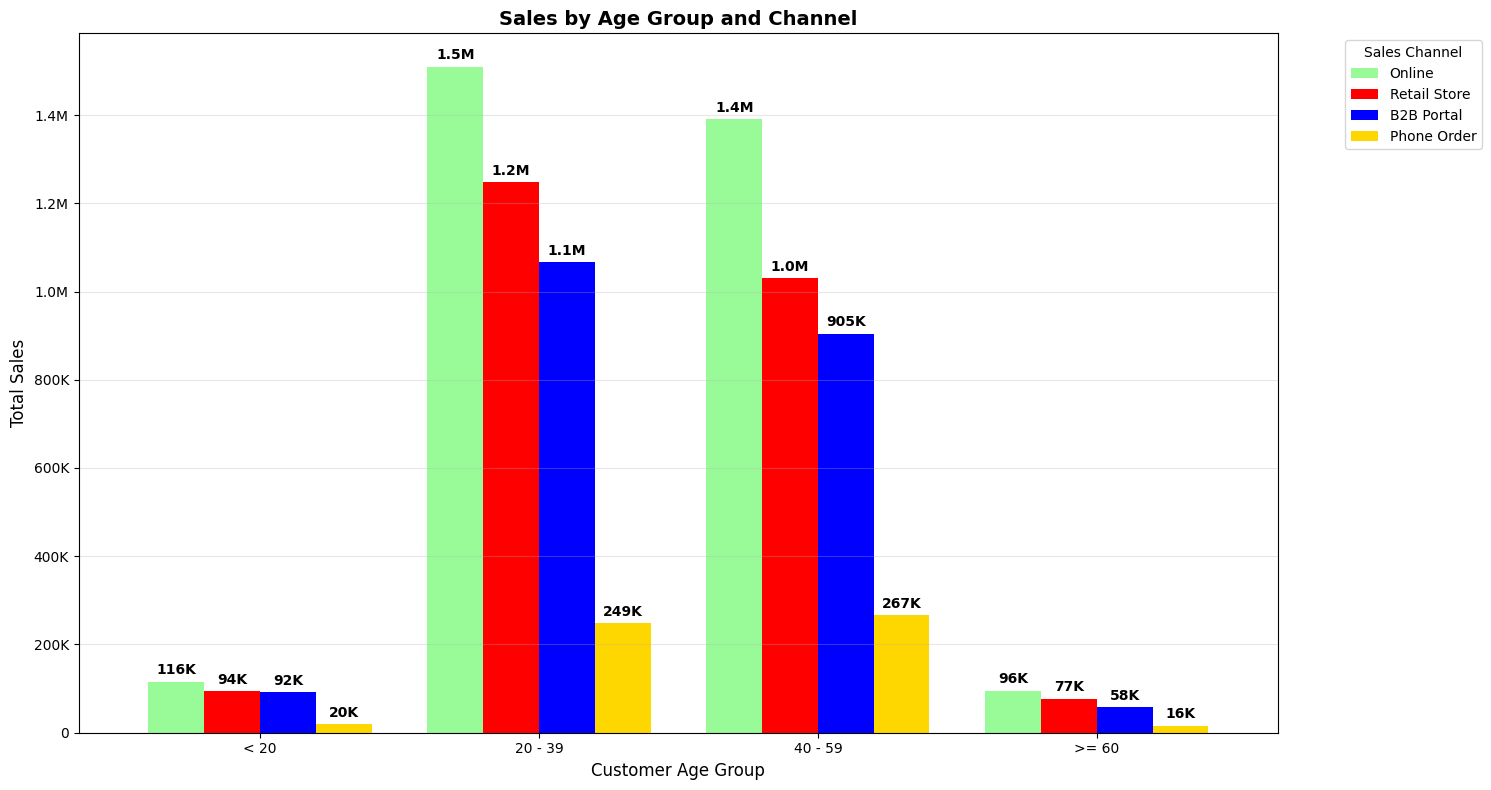

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# ===============================
# SALES BY AGE GROUP AND CHANNEL
# ===============================

# 1. Group data
age_channel = df.groupby(['Customer_Age_Group', 'Sales_Channel'])['Sales_Amount'].sum().unstack()

# 2. Reorder Age Groups (Youngest to Oldest)
age_order = ['< 20', '20 - 39', '40 - 59', '>= 60']
age_channel = age_channel.reindex([a for a in age_order if a in age_channel.index])

# 3. Reorder Channels and define Colors
channel_order = ['Online', 'Retail Store', 'B2B Portal', 'Phone Order']
channel_channel = [c for c in channel_order if c in age_channel.columns]
age_channel = age_channel[channel_channel]

color_map = {
    'Online': '#98FB98',       # Light Green
    'Retail Store': '#FF0000', # Red
    'B2B Portal': '#0000FF',   # Blue
    'Phone Order': '#FFD700'   # Gold / Yellow
}
colors = [color_map[c] for c in channel_channel]

# 4. Create Grouped Bar Chart
fig, ax = plt.subplots(figsize=(15, 8))

plot = age_channel.plot(kind='bar', color=colors, ax=ax, width=0.8)

# 5. Add Value Labels on top of bars
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# Loop through each container (each channel's bars)
for c in ax.containers:
    labels = [millions_formatter(v.get_height()) if v.get_height() > 0 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='edge', padding=3, fontsize=10, fontweight='bold')

# 6. Formatting
ax.set_xlabel('Customer Age Group', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)
ax.set_title('Sales by Age Group and Channel', fontweight='bold', fontsize=14)

# Format Y-Axis to M / K
ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# Customizing Legend and Grid
ax.legend(title='Sales Channel', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Rotate X-axis labels
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### **3. Product Performance**

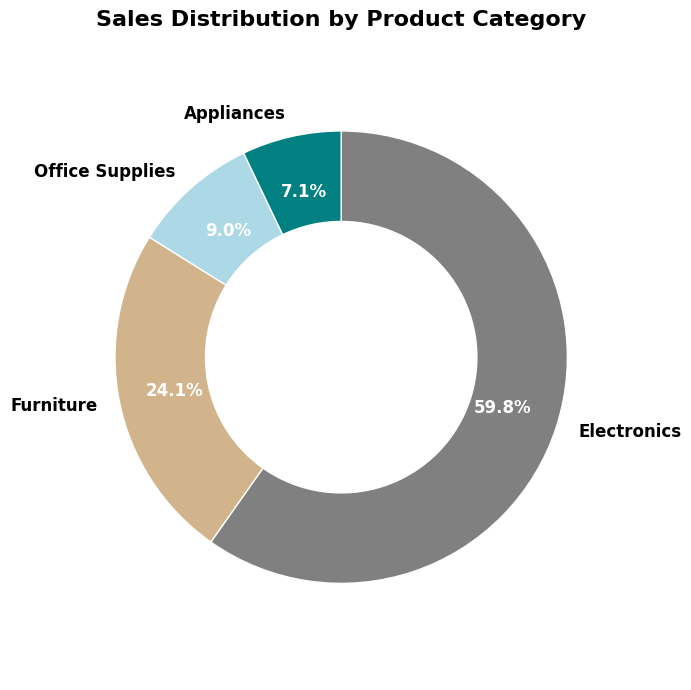

In [51]:
import pandas as pd
import matplotlib.pyplot as plt

# =======================================
# SALES DISTRIBUTION BY PRODUCT CATEGORY
# =======================================

# 1. Group data by Product Category and sum Sales_Amount
category_sales = df.groupby('Product_Category')['Sales_Amount'].sum()

# 2. Sort from largest to smallest
category_sales = category_sales.sort_values(ascending=False)

# 3. Set up colors based on instructions
color_map = {
    'Electronics': '#808080',        # Grey
    'Furniture': '#D2B48C',          # Light Brown
    'Office Supplies': '#ADD8E6',    # Light Blue
    'Appliances': '#008080'          # Dark Teal
}
# Map colors based on the sorted index
colors = [color_map.get(cat, '#cccccc') for cat in category_sales.index]

# 4. Create Donut Chart
fig, ax = plt.subplots(figsize=(7, 7))

# We use startangle=90 and counterclock=False to make it go clockwise from the top
wedges, texts, autotexts = ax.pie(
    category_sales,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,      # Force clockwise direction
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='w')
)

# 5. Customize text
for text in texts:
    text.set_fontsize(12)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    autotext.set_color('black' if autotext.get_text() in ['x'] else 'white') # Ensure text is readable on light colors

# 6. Add title
ax.set_title('Sales Distribution by Product Category', fontweight='bold', fontsize=16)

# 7. Draw a white circle in the middle for a cleaner donut look
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

# Ensure it's a perfect circle
ax.axis('equal')

plt.tight_layout()
plt.show()

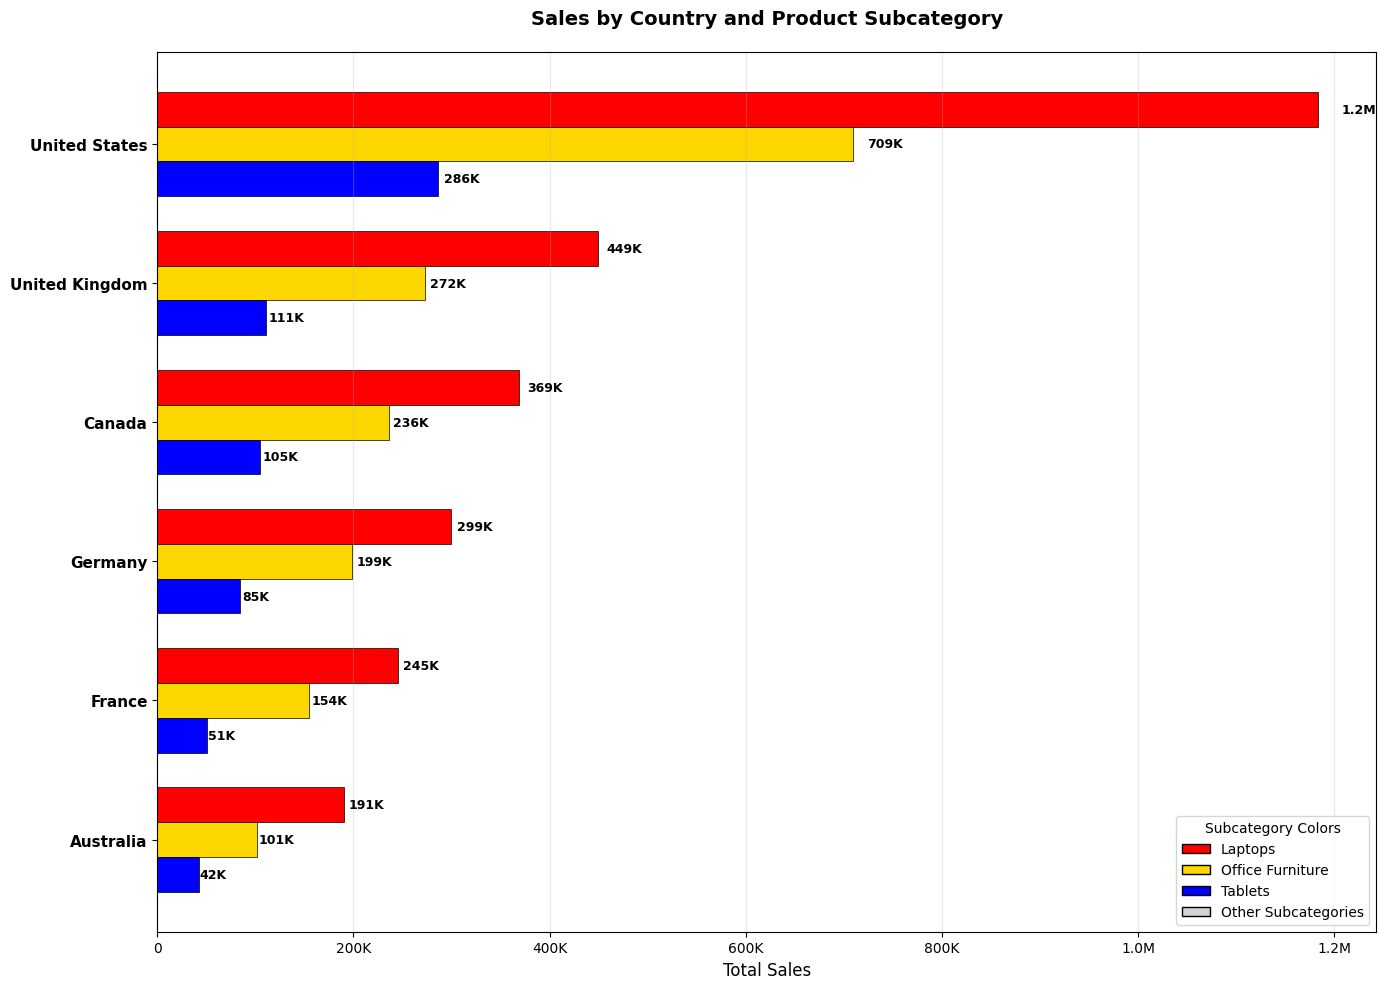

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

# =========================================
# SALES BY COUNTRY AND PRODUCT SUBCATEGORY
# =========================================

# 1. Group data and get Top 3
country_sub = df.groupby(['Country', 'Product_Subcategory'])['Sales_Amount'].sum().reset_index()
top3_per_country = country_sub.sort_values(['Country', 'Sales_Amount'], ascending=[True, False]).groupby('Country').head(3)
top3_per_country['Rank'] = top3_per_country.groupby('Country').cumcount() + 1

pivot_top3 = top3_per_country.pivot(index='Country', columns='Rank', values='Sales_Amount')
pivot_labels = top3_per_country.pivot(index='Country', columns='Rank', values='Product_Subcategory')

# Sort Countries by Rank 1 sales (Descending: Highest at top)
pivot_top3 = pivot_top3.sort_values(by=1, ascending=False)
pivot_labels = pivot_labels.reindex(pivot_top3.index)

# 2. Define Colors
def get_color(subcategory):
    if subcategory == 'Laptops': return 'red'
    elif subcategory == 'Office Furniture': return 'gold'
    elif subcategory == 'Tablets': return 'blue'
    else: return 'lightgrey'

# 3. Plotting
fig, ax = plt.subplots(figsize=(14, 10))
height = 0.25

# 4. Format function for M/K
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# 5. Loop through countries and draw bars manually
for i, country in enumerate(pivot_top3.index):
    # Base position for this country
    y_pos = i

    # Loop through Rank 1, 2, and 3
    for rank in [1, 2, 3]:
        value = pivot_top3.loc[country, rank]
        label = pivot_labels.loc[country, rank]

        if pd.notna(value):
            color = get_color(label)

            # Calculate the vertical position for this specific bar
            # Rank 1 is at the top (y_pos - 0.25), Rank 3 is at the bottom (y_pos + 0.25)
            bar_y = y_pos - (0.25 * (2 - rank))

            # Draw the bar
            bar = ax.barh(bar_y, value, height, color=color, edgecolor='black', linewidth=0.5)

            # Add value label
            ax.text(value + (value * 0.02), bar_y,
                    millions_formatter(value), va='center', ha='left', fontsize=9, fontweight='bold')

# 6. Formatting
# Set Y-ticks to the base position of each country
ax.set_yticks(np.arange(len(pivot_top3.index)))
ax.set_yticklabels(pivot_top3.index, fontsize=11, fontweight='bold')

# Invert Y-axis so Country 1 is at the very top
ax.invert_yaxis()

ax.set_xlabel('Total Sales', fontsize=12)
ax.set_title('Sales by Country and Product Subcategory', fontweight='bold', fontsize=14, pad=20)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))
ax.grid(axis='x', alpha=0.3)

# 7. Legend
legend_elements = [
    Patch(facecolor='red', edgecolor='black', label='Laptops'),
    Patch(facecolor='gold', edgecolor='black', label='Office Furniture'),
    Patch(facecolor='blue', edgecolor='black', label='Tablets'),
    Patch(facecolor='lightgrey', edgecolor='black', label='Other Subcategories')
]
ax.legend(handles=legend_elements, title='Subcategory Colors', loc='lower right')

plt.tight_layout()
plt.show()

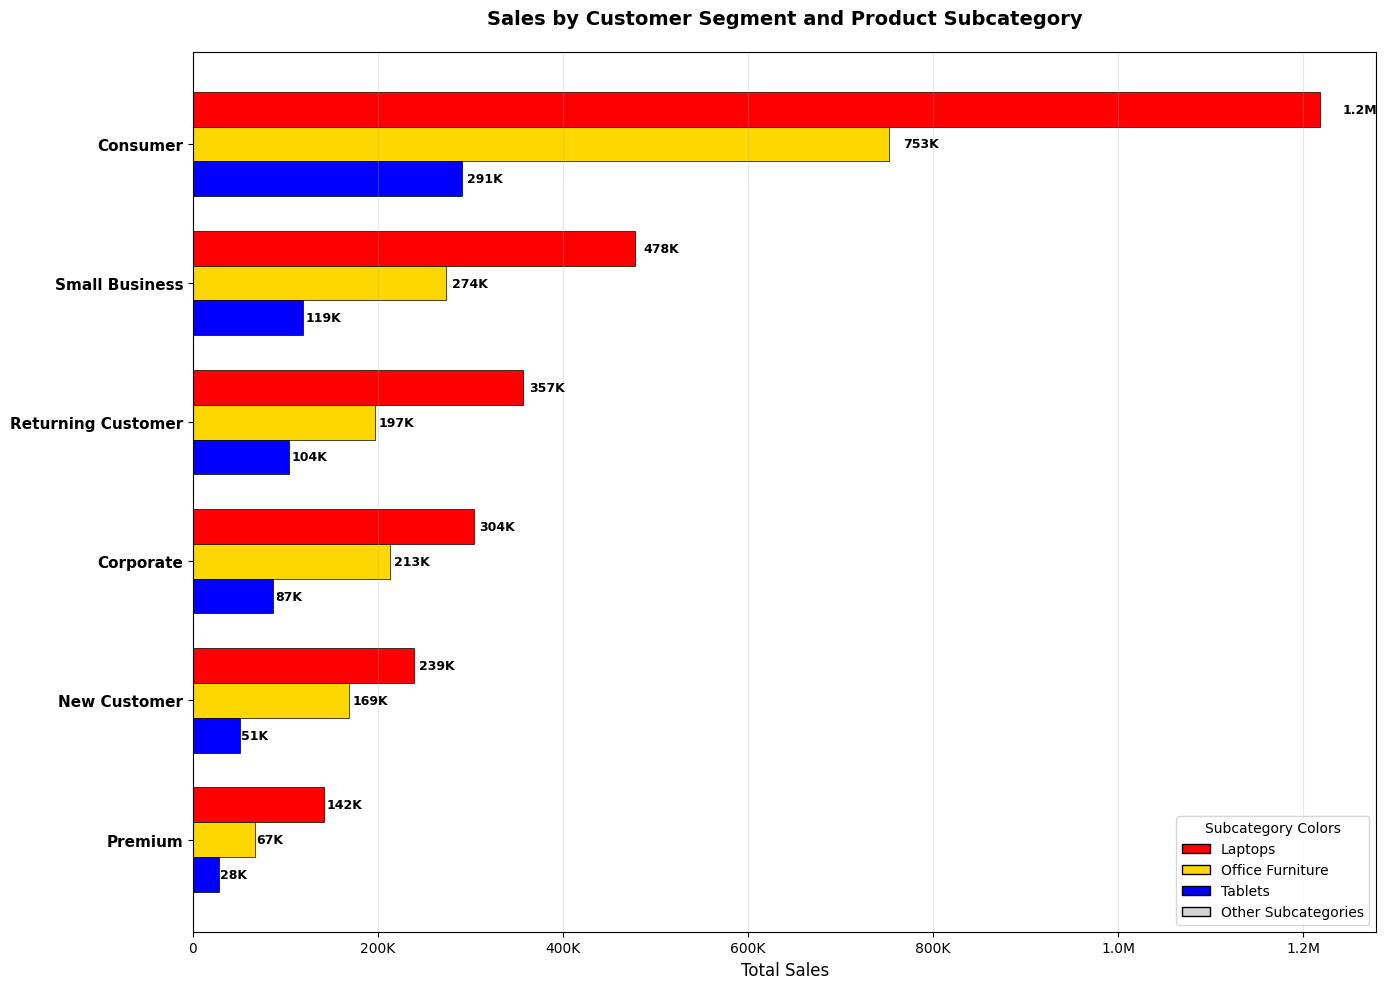

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

# =======================================================
# EDA: SALES BY CUSTOMER SEGMENT AND PRODUCT SUBCATEGORY
# =======================================================

# 1. Group data and get Top 3
segment_sub = df.groupby(['Customer_Segment', 'Product_Subcategory'])['Sales_Amount'].sum().reset_index()
top3_per_segment = segment_sub.sort_values(['Customer_Segment', 'Sales_Amount'], ascending=[True, False]).groupby('Customer_Segment').head(3)
top3_per_segment['Rank'] = top3_per_segment.groupby('Customer_Segment').cumcount() + 1

pivot_top3 = top3_per_segment.pivot(index='Customer_Segment', columns='Rank', values='Sales_Amount')
pivot_labels = top3_per_segment.pivot(index='Customer_Segment', columns='Rank', values='Product_Subcategory')

# 2. Sort Segments by Rank 1 sales (Descending: Highest at top)
pivot_top3 = pivot_top3.sort_values(by=1, ascending=False)
pivot_labels = pivot_labels.reindex(pivot_top3.index)

# 3. Define Colors
def get_color(subcategory):
    if subcategory == 'Laptops': return 'red'
    elif subcategory == 'Office Furniture': return 'gold'
    elif subcategory == 'Tablets': return 'blue'
    else: return 'lightgrey'

# 4. Plotting
fig, ax = plt.subplots(figsize=(14, 10))
height = 0.25

# 5. Format function for M/K
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# 6. Loop through segments and draw bars manually (Rank 1 at top)
for i, segment in enumerate(pivot_top3.index):
    y_pos = i

    for rank in [1, 2, 3]:
        value = pivot_top3.loc[segment, rank]
        label = pivot_labels.loc[segment, rank]

        if pd.notna(value):
            color = get_color(label)

            # Rank 1 is at the top (y_pos - 0.25), Rank 3 is at the bottom (y_pos + 0.25)
            bar_y = y_pos - (0.25 * (2 - rank))

            # Draw the bar
            bar = ax.barh(bar_y, value, height, color=color, edgecolor='black', linewidth=0.5)

            # Add value label
            ax.text(value + (value * 0.02), bar_y,
                    millions_formatter(value), va='center', ha='left', fontsize=9, fontweight='bold')

# 7. Formatting
ax.set_yticks(np.arange(len(pivot_top3.index)))
ax.set_yticklabels(pivot_top3.index, fontsize=11, fontweight='bold')

# Invert Y-axis so Segment 1 is at the very top
ax.invert_yaxis()

ax.set_xlabel('Total Sales', fontsize=12)
ax.set_title('Sales by Customer Segment and Product Subcategory', fontweight='bold', fontsize=14, pad=20)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))
ax.grid(axis='x', alpha=0.3)

# 8. Legend
legend_elements = [
    Patch(facecolor='red', edgecolor='black', label='Laptops'),
    Patch(facecolor='gold', edgecolor='black', label='Office Furniture'),
    Patch(facecolor='blue', edgecolor='black', label='Tablets'),
    Patch(facecolor='lightgrey', edgecolor='black', label='Other Subcategories')
]
ax.legend(handles=legend_elements, title='Subcategory Colors', loc='lower right')

plt.tight_layout()
plt.show()

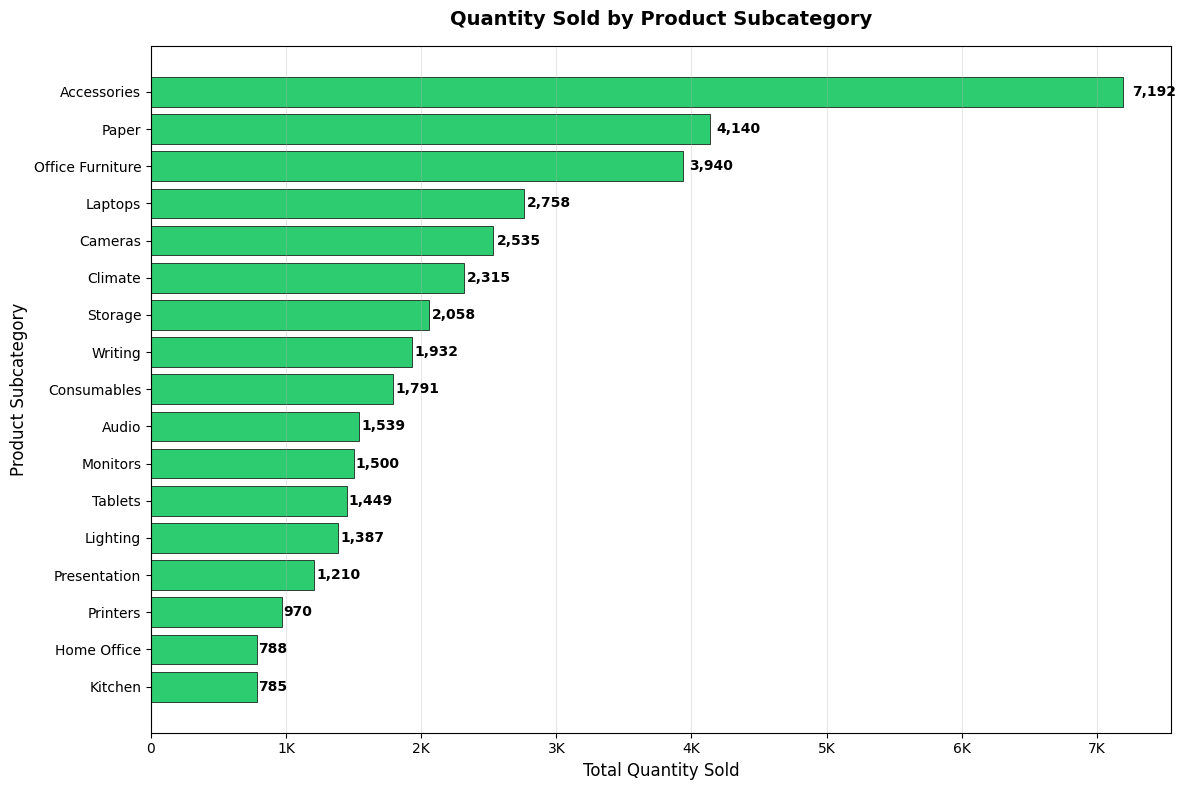

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# =====================================
# QUANTITY SOLD BY PRODUCT SUBCATEGORY
# =====================================

# 1. Group data by Subcategory and sum the Quantity
subcategory_qty = df.groupby('Product_Subcategory')['Quantity'].sum()

# 2. Sort from highest to lowest
subcategory_qty = subcategory_qty.sort_values(ascending=True) # Ascending for horizontal bar (highest at top)

# 3. Plotting
fig, ax = plt.subplots(figsize=(12, 8))

# Create horizontal bars
bars = ax.barh(subcategory_qty.index, subcategory_qty.values, color='#2ecc71', edgecolor='black', linewidth=0.5)

# 4. Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    # Format number with commas (e.g., 15,000)
    ax.text(width + (width * 0.01), bar.get_y() + bar.get_height()/2,
            f'{width:,.0f}', va='center', ha='left', fontsize=10, fontweight='bold')

# 5. Formatting
ax.set_xlabel('Total Quantity Sold', fontsize=12)
ax.set_ylabel('Product Subcategory', fontsize=12)
ax.set_title('Quantity Sold by Product Subcategory', fontweight='bold', fontsize=14, pad=15)

# Format X-Axis to K/M
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'
ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

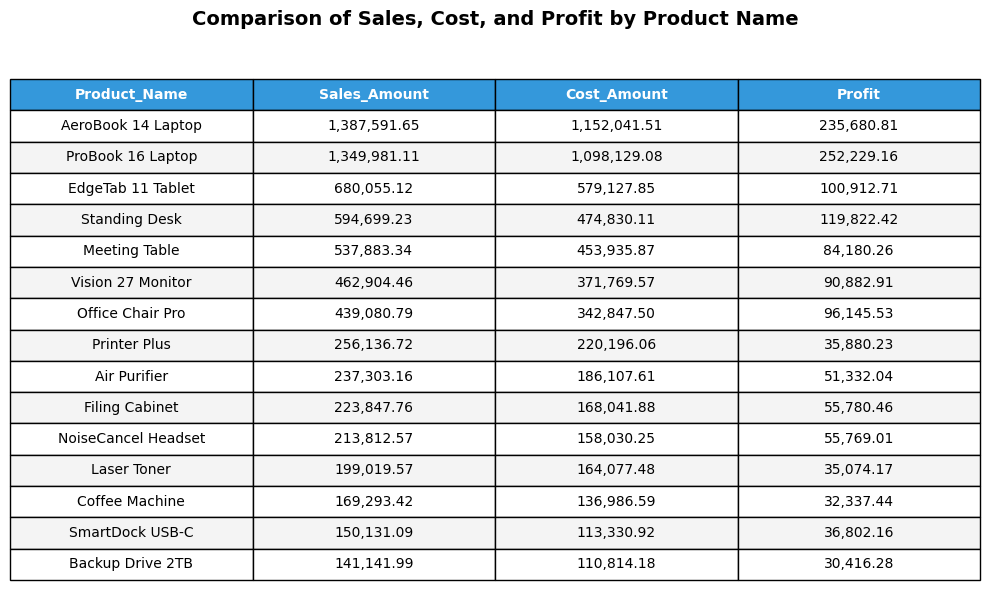

In [55]:
import pandas as pd
import matplotlib.pyplot as plt

# ======================================================
# COMPARISON OF SALES, COST, AND PROFIT BY PRODUCT NAME
# ======================================================

# 1. Group data by Product Name and sum Sales, Cost, and Profit
product_table = df.groupby('Product_Name')[['Sales_Amount', 'Cost_Amount', 'Profit']].sum()

# 2. Sort by Sales_Amount descending
product_table = product_table.sort_values(by='Sales_Amount', ascending=False)

# 3. Limit to Top 15 products
product_table = product_table.head(15)

# 4. Format numbers to 2 decimal places with commas
product_table['Sales_Amount'] = product_table['Sales_Amount'].apply(lambda x: f"{x:,.2f}")
product_table['Cost_Amount'] = product_table['Cost_Amount'].apply(lambda x: f"{x:,.2f}")
product_table['Profit'] = product_table['Profit'].apply(lambda x: f"{x:,.2f}")

# 5. Reset index to make 'Product_Name' a regular column
product_table = product_table.reset_index()

# 6. Set up the figure
fig, ax = plt.subplots(figsize=(10, 6))
ax.axis('off')

# 7. Create the table
table = ax.table(cellText=product_table.values,
                 colLabels=product_table.columns,
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 0.95])

# 8. Style the table
table.auto_set_font_size(False)
table.set_fontsize(10)

for (i, j), cell in table.get_celld().items():
    if i == 0:
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#3498db')
    else:
        cell.set_facecolor('#f4f4f4' if i % 2 == 0 else 'white')
    cell.set_edgecolor('black')

# 9. Add Title
plt.title('Comparison of Sales, Cost, and Profit by Product Name', fontweight='bold', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

### **4. Operational Performance**

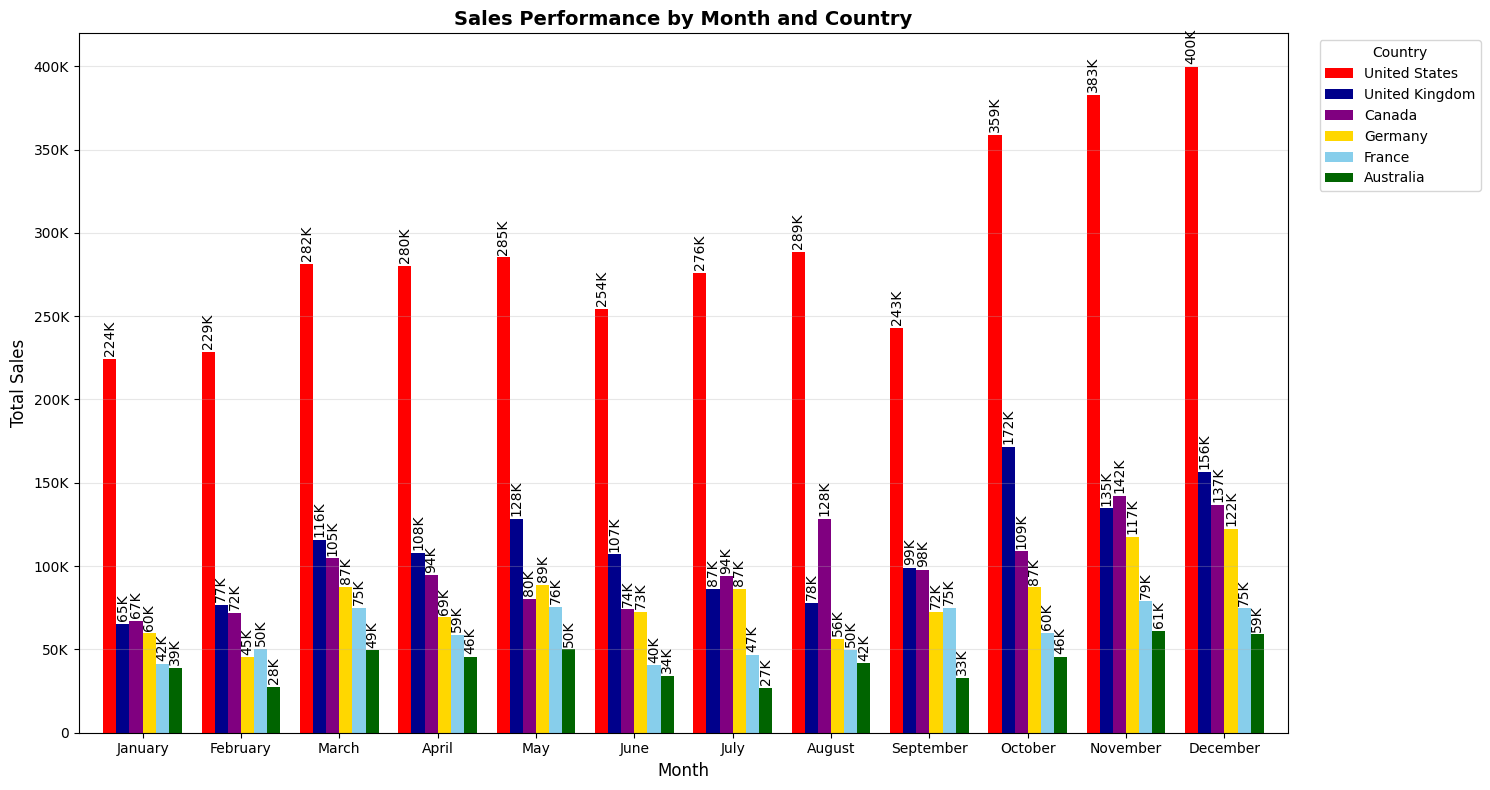

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# =======================================
# SALES PERFORMANCE BY MONTH AND COUNTRY
# =======================================

# 1. Group data
month_country = df.groupby(['Order_Month', 'Country'])['Sales_Amount'].sum().unstack()

# 2. Reorder Months
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
month_country = month_country.reindex([m for m in month_order if m in month_country.index])

# 3. Reorder Countries
country_order = ['United States', 'United Kingdom', 'Canada', 'Germany', 'France', 'Australia']
month_country = month_country.reindex(columns=[c for c in country_order if c in month_country.columns])

color_map = {
    'United States': 'red',
    'United Kingdom': 'darkblue',
    'Canada': 'purple',
    'Germany': 'gold',
    'France': 'skyblue',
    'Australia': 'darkgreen'
}
colors = [color_map[c] for c in month_country.columns]

# 4. Create Vertical Grouped Bar Chart
fig, ax = plt.subplots(figsize=(15, 8))

# Plot with grouped bars
plot = month_country.plot(kind='bar', color=colors, ax=ax, width=0.8)

# 5. Add Value Labels
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# Loop through each bar container to add labels
for c in ax.containers:
    # Format labels, ignore 0 values to reduce clutter
    labels = [millions_formatter(v.get_height()) if v.get_height() > 0 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='edge', padding=2, fontsize=10, rotation=90)

# 6. Formatting
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)
ax.set_title('Sales Performance by Month and Country', fontweight='bold', fontsize=14)

ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))
ax.legend(title='Country', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Rotate X-axis labels
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

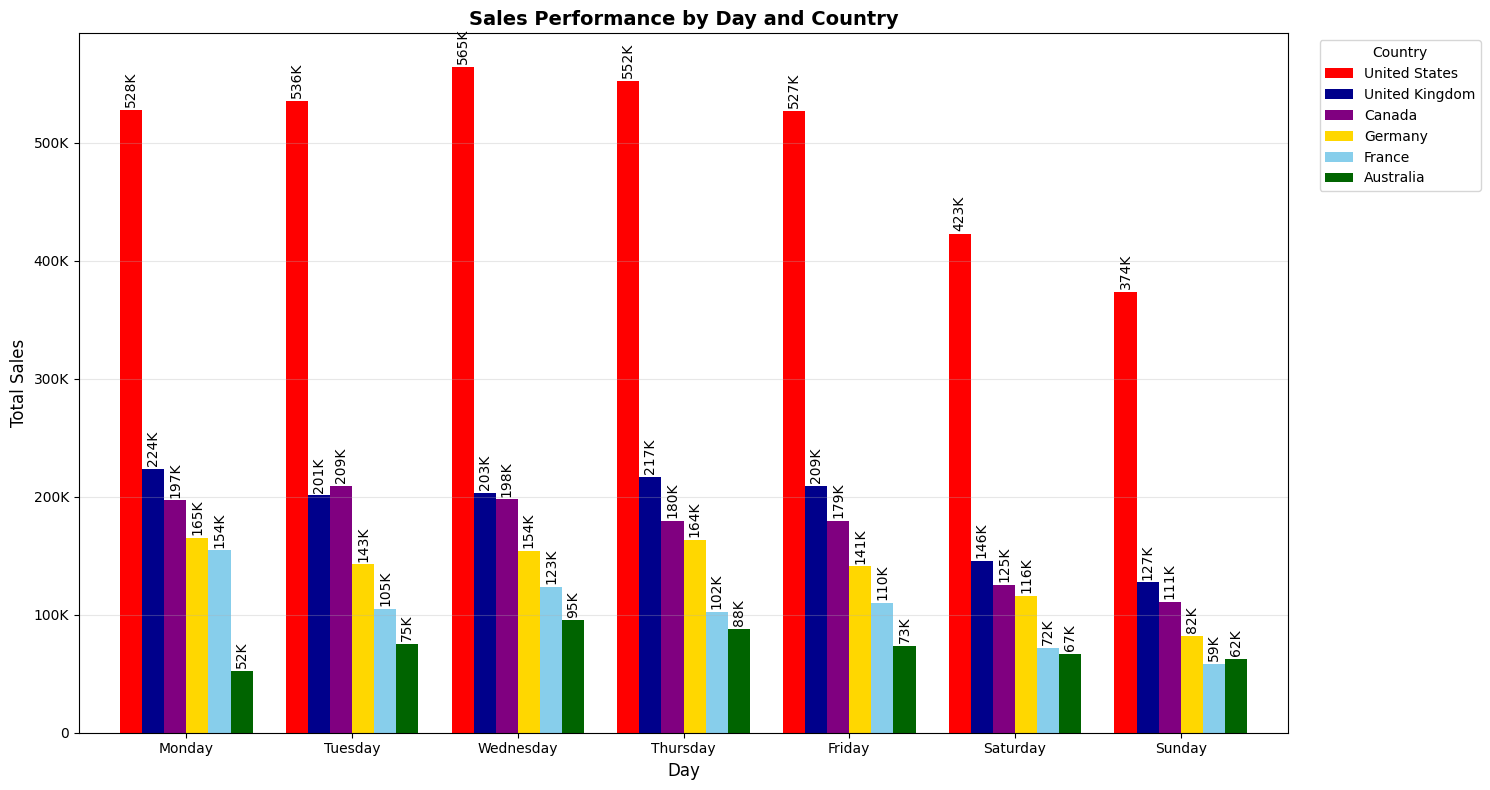

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# =======================================
# SALES PERFORMANCE BY DAY AND COUNTRY
# =======================================

# 1. Group data
day_country = df.groupby(['Order_Day', 'Country'])['Sales_Amount'].sum().unstack()

# 2. Reorder Days
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday',
               'Sunday']
day_country = day_country.reindex([m for m in day_order if m in day_country.index])

# 3. Reorder Countries
country_order = ['United States', 'United Kingdom', 'Canada', 'Germany', 'France', 'Australia']
day_country = day_country.reindex(columns=[c for c in country_order if c in day_country.columns])

color_map = {
    'United States': 'red',
    'United Kingdom': 'darkblue',
    'Canada': 'purple',
    'Germany': 'gold',
    'France': 'skyblue',
    'Australia': 'darkgreen'
}
colors = [color_map[c] for c in day_country.columns]

# 4. Create Vertical Grouped Bar Chart
fig, ax = plt.subplots(figsize=(15, 8))

# Plot with grouped bars
plot = day_country.plot(kind='bar', color=colors, ax=ax, width=0.8)

# 5. Add Value Labels
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

# Loop through each bar container to add labels
for c in ax.containers:
    # Format labels, ignore 0 values to reduce clutter
    labels = [millions_formatter(v.get_height()) if v.get_height() > 0 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='edge', padding=2, fontsize=10, rotation=90)

# 6. Formatting
ax.set_xlabel('Day', fontsize=12)
ax.set_ylabel('Total Sales', fontsize=12)
ax.set_title('Sales Performance by Day and Country', fontweight='bold', fontsize=14)

ax.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))
ax.legend(title='Country', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.3)

# Rotate X-axis labels
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

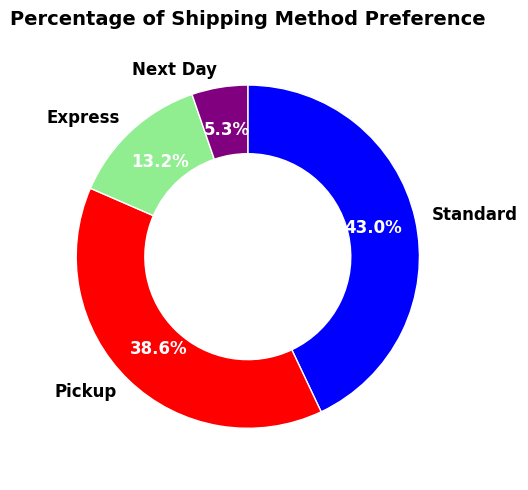

In [70]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================================
# PERCENTAGE OF SHIPPING METHOD PREFERENCE
# =========================================

# 1. Count the number of rows for each Shipping Method
shipping_counts = df['Shipping_Method'].value_counts()

# 2. Set up colors
color_map = {
    'Standard': 'blue',
    'Pickup': 'red',
    'Express': 'lightgreen',
    'Next Day': 'purple'
}
# Map colors to the data
colors = [color_map.get(method, '#cccccc') for method in shipping_counts.index]

# 3. Create Donut Chart
fig, ax = plt.subplots(figsize=(5, 5))

wedges, texts, autotexts = ax.pie(
    shipping_counts,
    labels=shipping_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,      # Clockwise
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='w')
)

# 4. Customize text
for text in texts:
    text.set_fontsize(12)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    # Make text white for dark backgrounds (except light green)
    autotext.set_color('white' if autotext.get_text() != 'Express' else 'black')

# 5. Add title
ax.set_title('Percentage of Shipping Method Preference', fontweight='bold', fontsize=14)

# 6. Draw a white circle in the middle
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

ax.axis('equal')

plt.tight_layout()
plt.show()

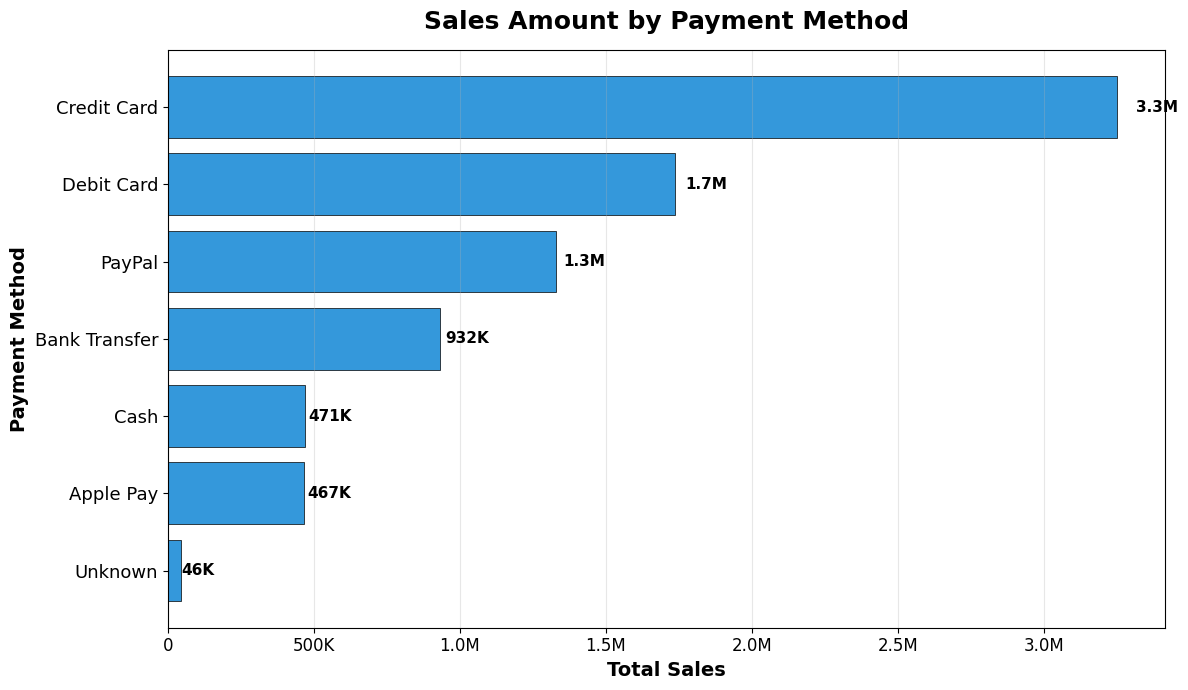

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ===============================
# SALES AMOUNT BY PAYMENT METHOD
# ===============================

# 1. Group data by Payment Method and sum Sales_Amount
payment_sales = df.groupby('Payment_Method')['Sales_Amount'].sum()

# 2. Sort from highest to lowest
payment_sales = payment_sales.sort_values(ascending=True)

# 3. Create the plot
fig, ax = plt.subplots(figsize=(12, 7))

# 4. Plot the bars
bars = ax.barh(payment_sales.index, payment_sales.values, color='#3498db', edgecolor='black', linewidth=0.5)

# 5. Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    # Format number with M/K
    if width >= 1_000_000:
        label = f'{width/1_000_000:.1f}M'
    elif width >= 1_000:
        label = f'{width/1_000:.0f}K'
    else:
        label = f'{width:.0f}'

    ax.text(width + (width * 0.02), bar.get_y() + bar.get_height()/2,
            label, va='center', ha='left', fontsize=11, fontweight='bold')

# 6. Formatting
ax.set_xlabel('Total Sales', fontsize=14, fontweight='bold')
ax.set_ylabel('Payment Method', fontsize=14, fontweight='bold')
ax.set_title('Sales Amount by Payment Method', fontweight='bold', fontsize=18, pad=15)

# Format X-Axis to M/K
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'
ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# Make tick labels bigger
ax.tick_params(axis='y', labelsize=13)
ax.tick_params(axis='x', labelsize=12)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

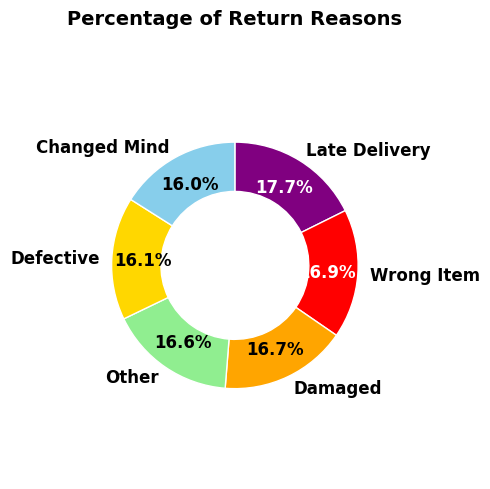

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================
# PERCENTAGE OF RETURN REASON
# ============================

# 1. Count the number of rows for each Return Reason
# Drop NaN first to calculate percentages for actual returns
return_counts = df['Return_Reason'].dropna().value_counts()

# 2. Set up colors
color_map = {
    'Late Delivery': 'purple',
    'Wrong Item': 'red',
    'Damaged': 'orange',
    'Other': 'lightgreen',
    'Defective': 'gold',
    'Changed Mind': 'skyblue'
}
# Map colors to the data
colors = [color_map.get(reason, '#cccccc') for reason in return_counts.index]

# 3. Create Donut Chart
fig, ax = plt.subplots(figsize=(5, 5))

wedges, texts, autotexts = ax.pie(
    return_counts,
    labels=return_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,      # Clockwise
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='w')
)

# 4. Customize text
for text in texts:
    text.set_fontsize(12)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    # Change text color to black for light backgrounds (orange, lightgreen, gold, skyblue)
    # and white for dark backgrounds (purple, red)
    bg_color = color_map.get(autotext.get_text().split(' ')[0], '')

    # Since autotext text is the percentage, we need to check the wedge color instead
    pass

# White text for dark colors, black text for light colors.
for i, autotext in enumerate(autotexts):
    color_name = color_map.get(return_counts.index[i], '')
    if color_name in ['purple', 'red']:
        autotext.set_color('white')
    else:
        autotext.set_color('black')

# 5. Add title
ax.set_title('Percentage of Return Reasons', fontweight='bold', fontsize=14, pad=20)

# 6. Draw a white circle in the middle
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

ax.axis('equal')

plt.tight_layout()
plt.show()

### **5. Promotion Performance**

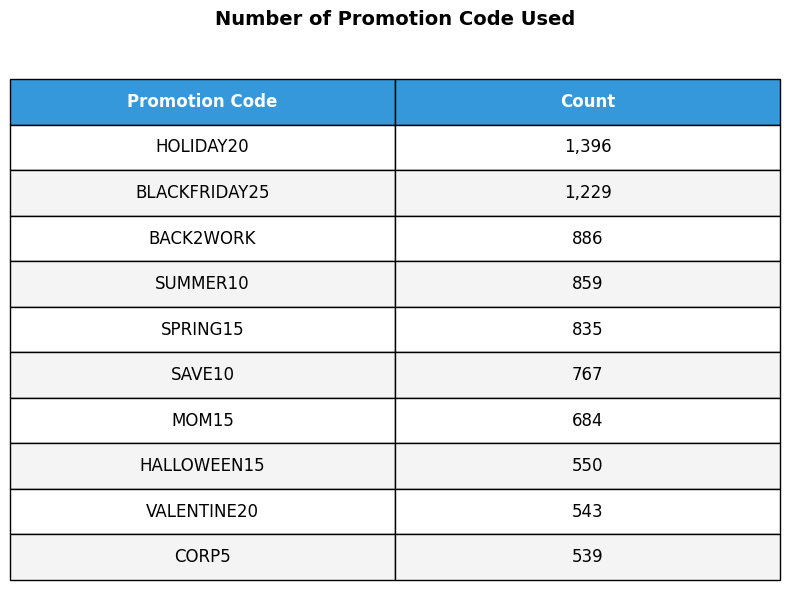

In [76]:
import pandas as pd
import matplotlib.pyplot as plt

# ==============================
# NUMBER OF PROMOTION CODE USED
# ==============================

# 1. Count the number of rows for each Promotion Code
# Drop NaN first to count actual promo codes used
promo_counts = df['Promotion_Code'].dropna().value_counts().reset_index()

# 2. Rename columns for the table
promo_counts.columns = ['Promotion Code', 'Count']

# 3. Format numbers with commas
promo_counts['Count'] = promo_counts['Count'].apply(lambda x: f"{x:,.0f}")

# 4. Set up the figure
fig, ax = plt.subplots(figsize=(8, 6))
ax.axis('off') # Hide axes

# 5. Create the table
table = ax.table(cellText=promo_counts.values,
                 colLabels=promo_counts.columns,
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 0.95])

# 6. Style the table
table.auto_set_font_size(False)
table.set_fontsize(12)

for (i, j), cell in table.get_celld().items():
    if i == 0: # Header row
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#3498db') # Blue header
    else:
        cell.set_facecolor('#f4f4f4' if i % 2 == 0 else 'white') # Zebra stripes
    cell.set_edgecolor('black')

# 7. Add Title
plt.title('Number of Promotion Code Used', fontweight='bold', fontsize=14, pad=20)

plt.tight_layout()
plt.show()

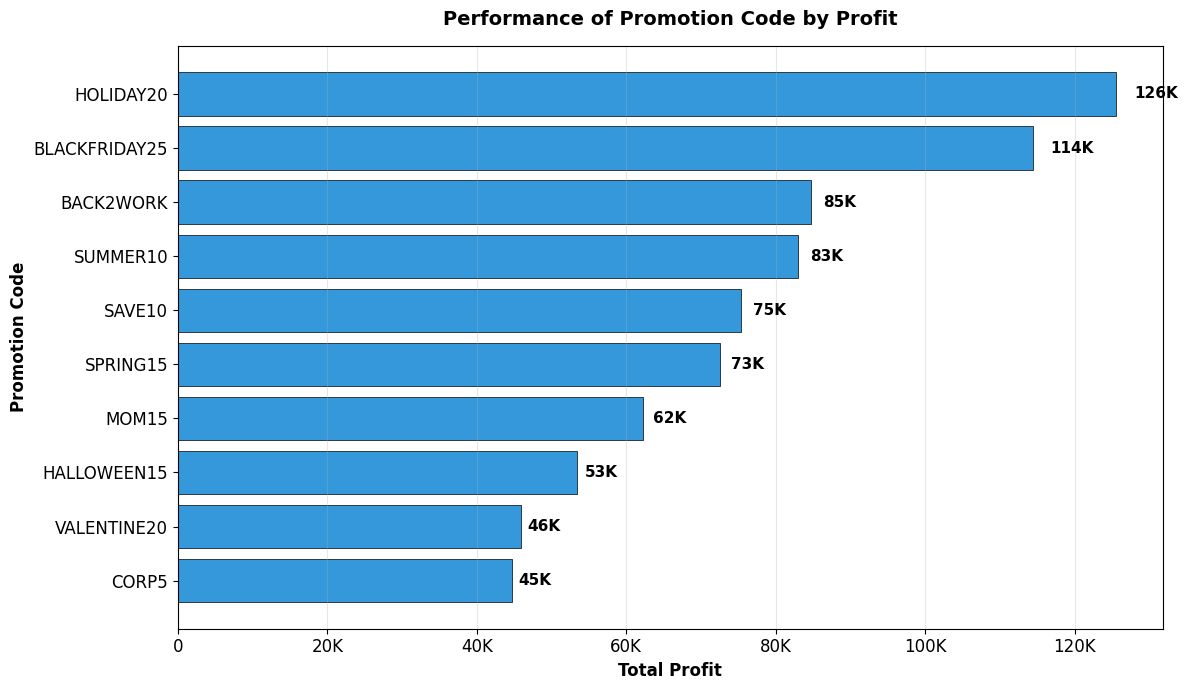

In [77]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# =============================================
# EDA: PERFORMANCE OF PROMOTION CODE BY PROFIT
# =============================================

# 1. Group data by Promotion Code and sum Profit
# Drop NaN first to caclculate actual promo codes
promo_profit = df.dropna(subset=['Promotion_Code']).groupby('Promotion_Code')['Profit'].sum()

# 2. Sort from highest to lowest
promo_profit = promo_profit.sort_values(ascending=True)

# 3. Create the plot
fig, ax = plt.subplots(figsize=(12, 7))

# 4. Plot horizontal bars (Color: Blue)
bars = ax.barh(promo_profit.index, promo_profit.values, color='#3498db', edgecolor='black', linewidth=0.5)

# 5. Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    # Format number with M/K
    if width >= 1_000_000:
        label = f'{width/1_000_000:.1f}M'
    elif width >= 1_000:
        label = f'{width/1_000:.0f}K'
    else:
        label = f'{width:.0f}'

    ax.text(width + (width * 0.02), bar.get_y() + bar.get_height()/2,
            label, va='center', ha='left', fontsize=11, fontweight='bold')

# 6. Formatting
ax.set_xlabel('Total Profit', fontsize=12, fontweight='bold')
ax.set_ylabel('Promotion Code', fontsize=12, fontweight='bold')
ax.set_title('Performance of Promotion Code by Profit', fontweight='bold', fontsize=14, pad=15)

# Format X-Axis to M/K
def millions_formatter(x, pos):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'
ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

# Make tick labels bigger
ax.tick_params(axis='y', labelsize=12)
ax.tick_params(axis='x', labelsize=12)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

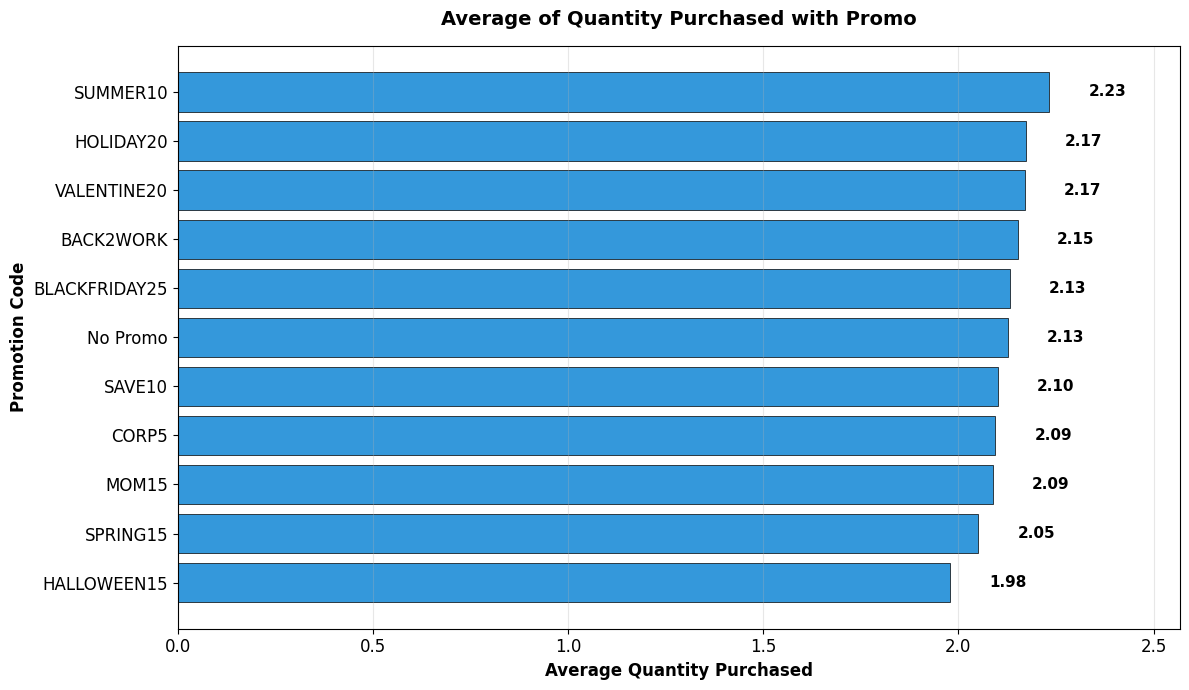

In [80]:
import pandas as pd
import matplotlib.pyplot as plt

# =========================================
# AVERAGE OF QUANTITY PURCHASED WITH PROMO
# =========================================

# 1. Fill missing Promotion Codes with "No Promo"
df['Promo_Clean'] = df['Promotion_Code'].fillna('No Promo')

# 2. Group by Promo_Clean and calculate the MEAN (average) of Quantity
promo_qty_avg = df.groupby('Promo_Clean')['Quantity'].mean()

# 3. Sort from highest to lowest
promo_qty_avg = promo_qty_avg.sort_values(ascending=True)

# 4. Create the plot
fig, ax = plt.subplots(figsize=(12, 7))

# 5. Plot the bars
bars = ax.barh(promo_qty_avg.index, promo_qty_avg.values, color='#3498db', edgecolor='black', linewidth=0.5)

# 6. Add value labels at the end of each bar
for bar in bars:
    width = bar.get_width()
    # Format to 2 decimal place
    ax.text(width + 0.1, bar.get_y() + bar.get_height()/2,
            f'{width:.2f}', va='center', ha='left', fontsize=11, fontweight='bold')

# 7. Formatting
ax.set_xlabel('Average Quantity Purchased', fontsize=12, fontweight='bold')
ax.set_ylabel('Promotion Code', fontsize=12, fontweight='bold')
ax.set_title('Average of Quantity Purchased with Promo', fontweight='bold', fontsize=14, pad=15)

# Make tick labels bigger
ax.tick_params(axis='y', labelsize=12)
ax.tick_params(axis='x', labelsize=12)
ax.grid(axis='x', alpha=0.3)

# Set a slight margin on the X-axis so the labels don't get cut off
ax.set_xlim(0, promo_qty_avg.max() * 1.15)

plt.tight_layout()
plt.show()

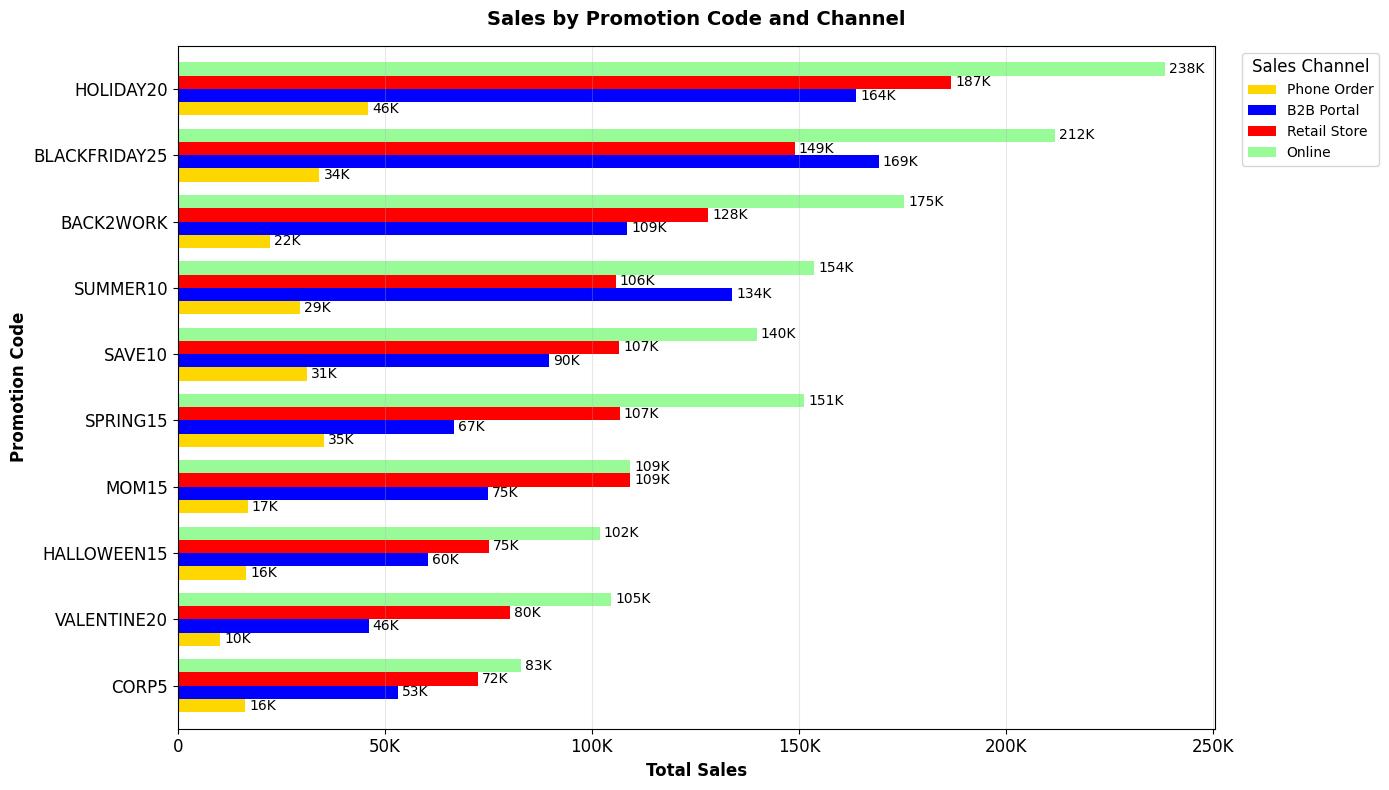

In [84]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# ====================================
# SALES BY PROMOTION CODE AND CHANNEL
# ====================================

# 1. Drop "No Promo" (NaN)
df_promo = df.dropna(subset=['Promotion_Code']).copy()

# 2. Group data by Promo and Channel
promo_channel = df_promo.groupby(['Promotion_Code', 'Sales_Channel'])['Sales_Amount'].sum().unstack(fill_value=0)

# 3. Reorder Channels
channel_order = ['Phone Order', 'B2B Portal', 'Retail Store', 'Online']
promo_channel = promo_channel.reindex(columns=[c for c in channel_order if c in promo_channel.columns])

# 4. Sort Promos by Total Sales
promo_totals = promo_channel.sum(axis=1)
promo_channel = promo_channel.loc[promo_totals.sort_values(ascending=True).index]

# 5. Define colors
color_map = {
    'Online': '#98FB98',       # Light Green
    'Retail Store': '#FF0000', # Red
    'B2B Portal': '#0000FF',   # Blue
    'Phone Order': '#FFD700'   # Gold/Yellow
}
colors = [color_map[c] for c in promo_channel.columns]

# 6. Create Grouped Horizontal Bar Chart
fig, ax = plt.subplots(figsize=(14, 8))

# Plotting grouped bars
promo_channel.plot(kind='barh', color=colors, ax=ax, width=0.8)

# 7. Add Value Labels
def millions_formatter(x, pos=None):
    if x >= 1_000_000:
        return f'{x/1_000_000:.1f}M'
    elif x >= 1_000:
        return f'{x/1_000:.0f}K'
    else:
        return f'{x:.0f}'

for c in ax.containers:
    labels = [millions_formatter(v.get_width()) if v.get_width() > 0 else '' for v in c]
    ax.bar_label(c, labels=labels, label_type='edge', padding=3, fontsize=10)

# 8. Formatting
ax.set_xlabel('Total Sales', fontsize=12, fontweight='bold')
ax.set_ylabel('Promotion Code', fontsize=12, fontweight='bold')
ax.set_title('Sales by Promotion Code and Channel', fontweight='bold', fontsize=14, pad=15)

ax.xaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

ax.legend(title='Sales Channel', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10, title_fontsize=12)
ax.grid(axis='x', alpha=0.3)

ax.tick_params(axis='y', labelsize=12)
ax.tick_params(axis='x', labelsize=12)

plt.tight_layout()
plt.show()

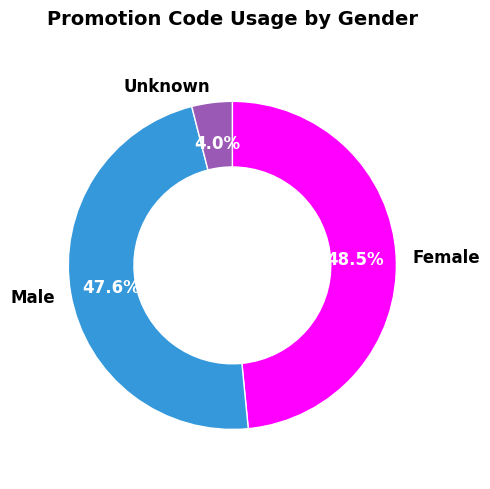

In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# ===============================
# PROMOTION CODE USAGE BY GENDER
# ===============================

# 1. Filter only rows where Promotion_Code is not NaN
df_promo = df.dropna(subset=['Promotion_Code']).copy()

# 2. Count the number of rows (transactions) for each Gender
gender_counts = df_promo['Customer_Gender'].value_counts()

# 3. Set up colors based on instructions
color_map = {
    'Male': '#3498db',       # Blue
    'Female': '#ff00ff',     # Magenta
    'Unknown': '#9b59b6'     # Purple
}
# Map colors to the data
colors = [color_map.get(gender, '#cccccc') for gender in gender_counts.index]

# 4. Create Donut Chart
fig, ax = plt.subplots(figsize=(5, 5))

wedges, texts, autotexts = ax.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='w')
)

# 5. Customize text
for text in texts:
    text.set_fontsize(12)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(12)
    autotext.set_fontweight('bold')
    autotext.set_color('white') # White text inside the colored ring

# 6. Add title
ax.set_title('Promotion Code Usage by Gender', fontweight='bold', fontsize=14, pad=20)

# 7. Draw a white circle in the middle for a cleaner donut look
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

# Ensure it's a perfect circle
ax.axis('equal')

plt.tight_layout()
plt.show()

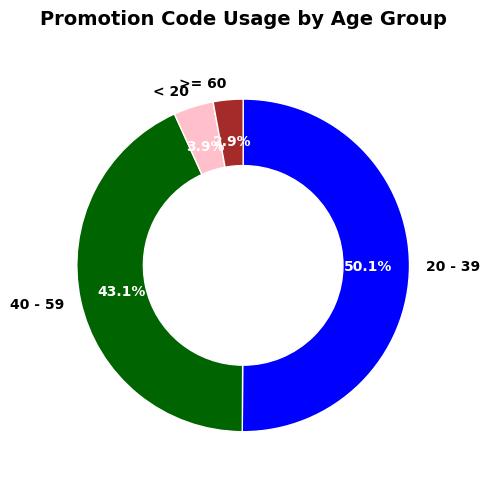

In [89]:
import pandas as pd
import matplotlib.pyplot as plt

# ===========================================
# PROMOTION CODE USAGE BY CUSTOMER AGE GROUP
# ===========================================

# 1. Filter only rows where Promotion_Code is not NaN
df_promo = df.dropna(subset=['Promotion_Code']).copy()

# 2. Count the number of rows for each Age Group
age_counts = df_promo['Customer_Age_Group'].value_counts()

# 3. Set up colors
color_map = {
    '< 20': 'pink',
    '20 - 39': 'blue',
    '40 - 59': 'darkgreen',
    '>= 60': 'brown'
}
colors = [color_map.get(age, '#cccccc') for age in age_counts.index]

# 4. Create Donut Chart
fig, ax = plt.subplots(figsize=(5, 5))

wedges, texts, autotexts = ax.pie(
    age_counts,
    labels=age_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(width=0.4, edgecolor='w')
)

# 5. Customize text
for text in texts:
    text.set_fontsize(10)
    text.set_fontweight('bold')

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('white') # White text inside the colored ring

# 6. Add title
ax.set_title('Promotion Code Usage by Age Group', fontweight='bold', fontsize=14, pad=20)

# 7. Draw a white circle in the middle for a cleaner donut look
centre_circle = plt.Circle((0,0),0.30,fc='white')
fig.gca().add_artist(centre_circle)

# Ensure it's a perfect circle
ax.axis('equal')

plt.tight_layout()
plt.show()